# Discourse first, then a constituency tree for each unit

The design agreed at the Oct 22 meeting, run step by step. Each step is code; run the cells in order.

| What was agreed on Oct 22 (time in the recording) | Where it is here |
|---|---|
| Run the discourse parse first (27:30, 33:40) | Step 1 |
| Run the constituency parse on each discourse unit, not on the whole sentence (27:30, 33:45) | Step 2 |
| Take the subjects and objects from each unit's constituency tree: the connections within a unit (33:45) | Step 3 |
| Use the discourse parse for the connections between units: unit 1 takes the subject of unit 0 ("inferential substitution", 28:20); "that is why" points to unit 0 and unit 1 together (29:35 to 30:25) | Step 4 |
| Only these two parsers: no dependency parse, nothing to reconcile (34:10) | Steps 1 to 4; checked in Part 7 |
| The same for French: the Quebec sentence gives "L'an dernier" as the frame and two facts (35:00 to 38:45) | Part 2 |
| Write the connections as "unit 0 and unit 1 to unit 2" (47:05) | every relation |
| The trees expanded, a tree inside a tree, drawn the way Mann and Thompson draw discourse trees (41:40 to 46:15) | Step 5 |
| Run it on more sentences from each legislature (40:25) | Part 4 |
| Keep every step in a data structure that can be read, to check what is in DBpedia (48:20) | Part 5 |

**Parsers.** On the Mac, with the project's venv, the cells below run the real parsers: isanlp_rst for the discourse parse, Stanza (English) and Berkeley benepar_fr2 (French) for the constituency parse of each unit. Anywhere else the notebook uses the parses saved on Oct 19 and says so at the top of each output.

**Answer keys.** The keys used in Part 7 were drafted with AI assistance; they are working keys, not a gold standard.

In [1]:
import os, sys, json, ast, random, math, collections, re, copy, time
from pathlib import Path
import pandas as pd
from IPython.display import display, SVG, HTML
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)

PROJECT = Path(os.environ.get("LHF_PROJECT", Path.home() / "MiscellaneousProjects" / "legislative-health-factuality"))
RULES = Path(os.environ.get("LHF_RULES", PROJECT / "scripts" / "v6"))
PARSES = Path(os.environ.get("LHF_PARSES", PROJECT / "data" / "parity_oct19" / "parity_parses.json"))
EDU_TREES = Path(os.environ.get("LHF_EDU_TREES", PROJECT / "outputs" / "edu" / "edu_trees.json"))
MORE = Path(os.environ.get("LHF_MORE", PROJECT / "outputs" / "edu" / "more_parses.json"))
OUTDIR = Path(os.environ.get("LHF_OUT", PROJECT / "outputs" / "edu"))
OUTDIR.mkdir(parents=True, exist_ok=True)

sys.argv = [sys.argv[0], str(RULES), str(PARSES)]
sys.path.insert(0, str(RULES))
import edu_pipeline as E          # the steps below call this file's functions
import edu_draw as D              # the tree-inside-a-tree figure
P = E.P
# every rule and key file is loaded from scripts/v6 now, before the parsers are imported: the parser module puts
# scripts/v4 (older copies of some of these files) at the front of Python's search path
import importlib
RULE_MODULES = ["preds", "lexicon", "const_fr", "combine_lib", "frames", "parity_score", "full", "compare3", "gold", "gold2",
                "gold_heldout", "parallel_tests", "edu_pipeline", "edu_draw"]
for m in RULE_MODULES:
    importlib.import_module(m)
E.OPT["units_only"] = True        # the Oct 22 design: only each unit's own tree and the discourse parse

ROWS = json.load(open(PARSES, encoding="utf-8"))["rows"]
BY_N = {r["n"]: r for r in ROWS}
BY_TEXT = {r["text"]: r for r in ROWS}
REPARSED = json.load(open(EDU_TREES, encoding="utf-8")) if EDU_TREES.exists() else {}

LIVE, WHY = False, ""
if os.environ.get("LHF_LIVE", "1") != "0":
    try:
        sys.path.insert(1, str(PROJECT / "scripts" / "v4"))
        import parse_corpus_v5 as V
        assert V.P is P, "parse_corpus_v5 loaded another copy of the rules"
        LIVE = True
    except Exception as ex:                       # noqa: BLE001
        WHY = f"{type(ex).__name__}: {ex}"
    finally:
        v4 = str(PROJECT / "scripts" / "v4")
        sys.path[:] = [x for x in sys.path if x != v4] + [v4]      # scripts/v6 first again; v4 only for the parsers
print("parsers:", "live (isanlp_rst, Stanza, Berkeley benepar_fr2)" if LIVE else f"not loaded here ({WHY[:80]}); using the parses saved Oct 19")
print("units parsed on their own, saved:", f"{len(REPARSED)} sentences" if REPARSED else "none yet (run_edu.sh makes them)")
print(f"saved sentences: {len(ROWS)}")
WRONG = {m: sys.modules[m].__file__ for m in RULE_MODULES if Path(sys.modules[m].__file__).resolve().parent != RULES.resolve()}
print("rules and keys loaded from:", RULES, "(all of them)" if not WRONG else f"-- NOT ALL: {WRONG}")

parsers: live (isanlp_rst, Stanza, Berkeley benepar_fr2)
units parsed on their own, saved: 280 sentences
saved sentences: 220
rules and keys loaded from: /Users/caprice/MiscellaneousProjects/legislative-health-factuality/scripts/v6 (all of them)


In [2]:
def tree_of(text, lang):
    "Step 2 for one piece of text: its constituency tree(s), read the same way as the full corpus run."
    if lang == "en":
        doc = V.stanza_model("en")(text)
        return [P.from_stanza_tree(x.constituency) for x in doc.sentences if getattr(x, "constituency", None) is not None]
    bp = V.berkeley()
    if bp is None:
        return []
    trees, _ = V.berkeley_trees(bp, V.BEN["mod"], V.spacy_model("fr")(text))
    return trees

def edus_of(row):
    d = row.get("disc_native") or {}
    edus = d.get("edus") or [{"text": row["text"], "start": 0, "end": len(row["text"])}]
    return E.reanchor(edus, row["text"])

def step1(text, lang, n=None):
    "Step 1: the discourse parse. Live on the Mac; otherwise the saved parse of this sentence."
    if LIVE:
        d, status = V.rst_parse(text, lang)
        return {"n": n or "(typed)", "set": "typed", "lang": lang, "text": text, "trees": [], "disc_native": d, "disc_native_status": status}, "parsed now"
    row = BY_N.get(n) or BY_TEXT.get(text)
    if row is None:
        raise ValueError("no parsers here and this sentence was not saved; run this on the Mac")
    return row, "saved Oct 19"

def step2(row):
    "Step 2: a constituency tree for each unit, parsing the unit's own text."
    if LIVE and row.get("set") == "typed":
        return [tree_of(e["text"].strip(), row["lang"]) for e in edus_of(row)], "each unit parsed now"
    if row["n"] in REPARSED:
        return REPARSED[row["n"]], "each unit parsed on its own (saved by run_edu.sh)"
    # stand-in until run_edu.sh has run: the sentence's saved tree cut down to each unit's words
    return [[t for t, _ in ps] for ps in E.unit_trees(row, edus_of(row))], "STAND-IN: the sentence's tree cut to each unit (run_edu.sh parses each unit alone)"

WITHIN_ONLY = {"discourse_subject": False, "demonstrative": False, "said_object": False, "frame_context": False, "relpron": False, "apposition_across": False}

def run(row, trees, opt=None):
    saved = dict(E.OPT)
    try:
        E.OPT.update(opt or {})
        return E.process(row, trees)
    finally:
        E.OPT.clear(); E.OPT.update(saved)

def relation_table(rec):
    return pd.DataFrame([{"connection": c["from"] + " to " + c["to"], "relation": c["relation"], "parser's own label": c.get("parser_label", ""), "main part": c["main"],
                          "how it reads": c["reads"].split(": ", 1)[1]} for c in rec["connections"]])

def lines_table(rec, with_source=True):
    out = []
    for l in rec["lines"]:
        d = {"unit": l["unit"], "subject": l["subject"], "verb": l["verb"], "verb form": "to-infinitive" if l.get("infinitive") else "", "object": l["object"]}
        if with_source:
            d["where the subject came from"] = l.get("subject_from") or "its own unit"
            d["object from"] = l.get("object_from") or ""
            d["context"] = "; ".join(l.get("context") or [])
            d["that = "] = (l.get("refers_to") or "")
        out.append(d)
    return pd.DataFrame(out)

def walk_through(text, lang, n=None):
    row, src1 = step1(text, lang, n)
    print(f"Sentence: {row['text']}\n")
    print(f"STEP 1. Discourse parse ({src1}): the units")
    edus = edus_of(row)
    display(pd.DataFrame([{"unit": i, "text": e["text"].strip()} for i, e in enumerate(edus)]))
    rec0 = run(row, None)                    # only to read the relations in the shared wording
    print("        and how the discourse parse connects them")
    display(relation_table(rec0))
    trees, src2 = step2(row)
    print(f"\nSTEP 2. A constituency tree for each unit ({src2})")
    within = run(row, trees, WITHIN_ONLY)
    for u in within["units"]:
        print(f"   unit {u['unit']}: " + "  ".join(u["tree"]))
    print("\nSTEP 3. Subject | verb | object read from each unit's own tree (connections within a unit; nothing taken from other units yet)")
    display(lines_table(within, with_source=False))
    rec = run(row, trees)
    print("\nSTEP 4. The discourse parse connects the units: a gap in a unit is filled from the unit it is connected to, and 'that' is read as the units it points to")
    display(lines_table(rec))
    print("\nSTEP 5. The tree inside a tree")
    display(SVG(D.figure(rec)))
    return rec

## Part 1. The English sentence from the meeting

*A small hardware store in an AHP would be joining an association, sending their premiums not to themselves but off to others, and that is why we need the check.*

What was said should come out (28:20 to 32:30): unit 0 is a fact on its own (the store would be joining an association); unit 1 elaborates unit 0, so its subject is the subject of unit 0 (the store is sending its premiums to others); unit 2 explains unit 0 and unit 1 together, so "that" is all of unit 0 and unit 1; and inside unit 2, we need the check.

14:54:31    loaded the discourse parser (UniRST) in 16.8s
Sentence: A small hardware store in an AHP would be joining an association, sending their premiums not to themselves but off to others, and that is why we need the check.

STEP 1. Discourse parse (parsed now): the units


,unit,text
0,0,"A small hardware store in an AHP would be joining an association,"
1,1,"sending their premiums not to themselves but off to others,"
2,2,and that is why we need the check.


        and how the discourse parse connects them


,connection,relation,parser's own label,main part,how it reads
0,unit 0 to unit 1,elaboration,elaboration,unit 0,elaboration; main part unit 0; unit 1 adds detail to unit 0
1,unit 0 and unit 1 to unit 2,explanation,explanation,unit 2,explanation; main part unit 2; unit 0 and unit 1 give the reason for unit 2


14:54:32    loaded Stanza en 1.15.0 (constituency: yes) in 1.4s

STEP 2. A constituency tree for each unit (each unit parsed now)
   unit 0: (ROOT (S (NP (NP (DT A) (JJ small) (NN hardware) (NN store)) (PP (IN in) (NP (DT an) (NNP AHP)))) (VP (MD would) (VP (VB be) (VP (VBG joining) (NP (DT an) (NN association))))) (, ,)))
   unit 1: (ROOT (S (VP (VBG sending) (NP (PRP$ their) (NNS premiums)) (PP (RB not) (PP (IN to) (NP (PRP themselves))) (CC but) (PP (RP off) (PP (IN to) (NP (NNS others)))))) (, ,)))
   unit 2: (ROOT (S (CC and) (NP (DT that)) (VP (VBZ is) (SBAR (WHADVP (WRB why)) (S (NP (PRP we)) (VP (VBP need) (NP (DT the) (NN check)))))) (. .)))

STEP 3. Subject | verb | object read from each unit's own tree (connections within a unit; nothing taken from other units yet)


,unit,subject,verb,verb form,object
0,0,A small hardware store in an AHP,would be joining,,an association
1,1,(unstated),sending,,their premiums
2,2,that,is,,why we need the check
3,2,we,need,,the check



STEP 4. The discourse parse connects the units: a gap in a unit is filled from the unit it is connected to, and 'that' is read as the units it points to


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,0,A small hardware store in an AHP,would be joining,,an association,its own unit,,,
1,1,A small hardware store in an AHP,sending,,their premiums,unit 0 (elaboration),,,
2,2,that,is,,why we need the check,'that' points to unit 0 and unit 1 (explanation),,,"unit 0 and unit 1: A small hardware store in an AHP would be joining an association, s..."
3,2,we,need,,the check,its own unit,,,



STEP 5. The tree inside a tree


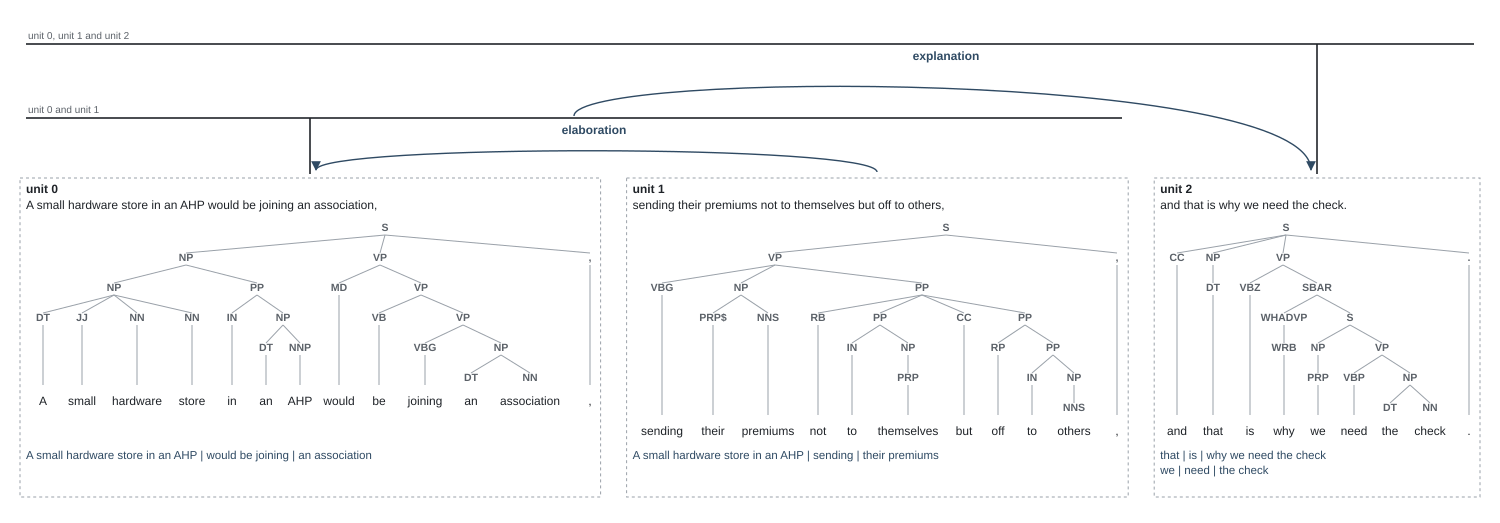

In [3]:
REC_EN = walk_through("A small hardware store in an AHP would be joining an association, sending their premiums not to themselves but off to others, and that is why we need the check.", "en", "sample|1")

## Part 2. The French sentence from the meeting

*L'an dernier, la Chambre a adopté un projet de loi identique au projet de loi 5, mais le Sénat a refusé d'agir.*

What was said should come out (35:00 to 38:45): unit 1 and unit 2 are a contrast; unit 0, "L'an dernier", is the frame for both; and the facts are that the Chambre adopted a bill identical to bill 5, and that the Senate refused to act, both last year. The same steps as for English.

Sentence: L'an dernier, la Chambre a adopté un projet de loi identique au projet de loi 5, mais le Sénat a refusé d'agir.

STEP 1. Discourse parse (parsed now): the units


,unit,text
0,0,"L'an dernier,"
1,1,"la Chambre a adopté un projet de loi identique au projet de loi 5,"
2,2,mais le Sénat a refusé d'agir.


        and how the discourse parse connects them


,connection,relation,parser's own label,main part,how it reads
0,unit 1 to unit 2,contrast,contrast,both,contrast; both equally important
1,unit 0 to unit 1 and unit 2,background,frame,unit 0,background; main part unit 0; unit 1 and unit 2 give background or context for unit 0


14:54:42    loaded the Berkeley parser (benepar_fr2) in 9.3s; fixes: added torch._six (removed in torch 2); rebuilt build_inputs_with_special_tokens for XLMRobertaTokenizer (removed in transformers 5); position_ids: dropped 1 extra, filled 0 missing (transformers change)
14:54:44    loaded spaCy fr (core_news_lg 3.8.0) in 2.2s

STEP 2. A constituency tree for each unit (each unit parsed now)
   unit 0: (TOP (SENT (NP (DET L') (NC an) (AP (ADJ dernier))) (PONCT ,)))
   unit 1: (TOP (SENT (NP (DET la) (NC Chambre)) (VN (V a) (VPP adopté)) (NP (DET un) (NC+ (NC projet) (P de) (NC loi)) (AP (ADJ identique) (PP (P+D au) (NP (NC+ (NC projet) (P de) (NC loi)) (ADJ 5))))) (PONCT ,)))
   unit 2: (TOP (SENT (COORD (CC mais) (Sint (NP (DET le) (NPP Sénat)) (VN (V a) (VPP refusé)) (PP (P d') (VPinf (VN (VINF agir)))))) (PONCT .)))

STEP 3. Subject | verb | object read from each unit's own tree (connections within a unit; nothing taken from other units yet)


,unit,subject,verb,verb form,object
0,1,la Chambre,a adopté,,un projet de loi identique au projet de loi 5
1,2,le Sénat,a refusé d'agir,,



STEP 4. The discourse parse connects the units: a gap in a unit is filled from the unit it is connected to, and 'that' is read as the units it points to


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,1,la Chambre,a adopté,,un projet de loi identique au projet de loi 5,its own unit,,"L'an dernier (background, unit 0)",
1,2,le Sénat,a refusé d'agir,,,its own unit,,"L'an dernier (background, unit 0)",



STEP 5. The tree inside a tree


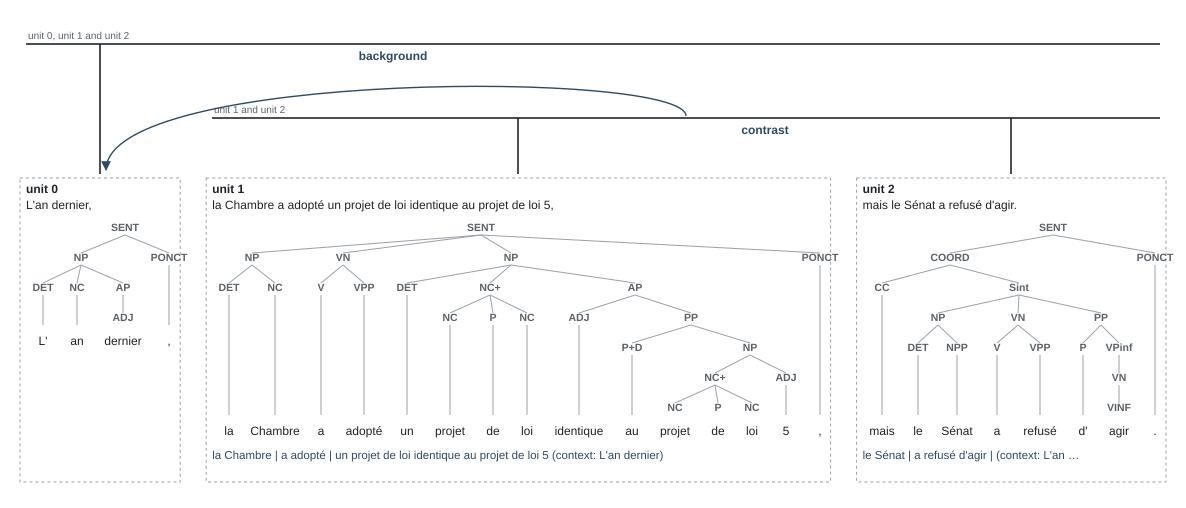

In [4]:
REC_FR = walk_through("L'an dernier, la Chambre a adopté un projet de loi identique au projet de loi 5, mais le Sénat a refusé d'agir.", "fr", "test|A8|fr")

## Part 3. Any sentence

Change `TEXT` and `LANG` and run the cell. On the Mac this parses the sentence now; elsewhere it only works for a saved sentence.

Sentence: Way back in the day, miners who went underground were constantly exposed to various types of carcinogens.

STEP 1. Discourse parse (parsed now): the units


,unit,text
0,0,"Way back in the day, miners"
1,1,who went underground
2,2,were constantly exposed to various types of carcinogens.


        and how the discourse parse connects them


,connection,relation,parser's own label,main part,how it reads
0,unit 0 to unit 1,elaboration,elaboration,unit 0,elaboration; main part unit 0; unit 1 adds detail to unit 0
1,unit 0 and unit 1 to unit 2,same-unit,same-unit,both,same-unit; both equally important



STEP 2. A constituency tree for each unit (each unit parsed now)
   unit 0: (ROOT (S (ADVP (NN Way) (RB back) (PP (IN in) (NP (DT the) (NN day)))) (, ,) (NP (NNS miners))))
   unit 1: (ROOT (SBAR (WHNP (WP who)) (S (VP (VBD went) (ADVP (RB underground))))))
   unit 2: (ROOT (S (VP (VBD were) (ADVP (RB constantly)) (VP (VBN exposed) (PP (IN to) (NP (NP (JJ various) (NNS types)) (PP (IN of) (NP (NNS carcinogens))))))) (. .)))

STEP 3. Subject | verb | object read from each unit's own tree (connections within a unit; nothing taken from other units yet)


,unit,subject,verb,verb form,object
0,1,,went,,underground
1,2,,were exposed,,to various types of carcinogens



STEP 4. The discourse parse connects the units: a gap in a unit is filled from the unit it is connected to, and 'that' is read as the units it points to


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,1,miners,went,,underground,'who' stands for the last noun phrase of unit 0 (discourse: elaboration),,,
1,2,miners,were exposed,,to various types of carcinogens,unit 0 (same-unit: the sentence goes on after an insertion),,,



STEP 5. The tree inside a tree


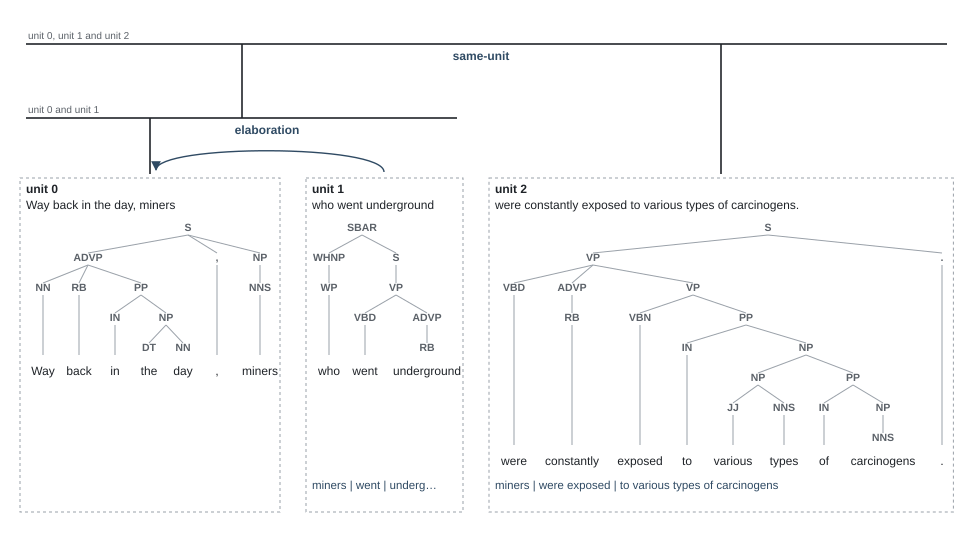

In [5]:
TEXT = "Way back in the day, miners who went underground were constantly exposed to various types of carcinogens."
LANG = "en"
_ = walk_through(TEXT, LANG)

## Part 4. More sentences from each legislature

On the Mac, `N_MORE` new sentences are drawn at random from each legislature's debate sentences (US House, Ontario, Quebec; seed 20261026; 8 to 60 words; none already in the answer keys; no quoted bill text) and run through steps 1 to 4. Without the parsers, the saved sentences are used, grouped by legislature, plus any new ones `run_edu.sh` saved.

In [6]:
N_MORE = int(os.environ.get("LHF_N_MORE", "20"))
JUR = {"US": ("us", "en", "US House"), "ON": ("ontario", "en", "Ontario"), "QC": ("quebec", "fr", "Quebec")}

def legislature(row):
    sid = row.get("sentence_id") or ""
    return JUR[sid[:2]][2] if sid[:2] in JUR else None

def draw_new(n):
    rnd = random.Random(20261026); taken = {r.get("sentence_id") for r in ROWS}; out = []
    for code_, (j, lang, name) in JUR.items():
        recs = json.load(open(PROJECT / "data" / "dbpedia_pipeline" / j / "sentences_v3.json", encoding="utf-8"))
        recs = [x for x in recs if x.get("sentence_id") and x.get("text") and x["sentence_id"] not in taken and 8 <= len(x["text"].split()) <= 60
                and not E.is_bill_text(x["text"])]
        rnd.shuffle(recs)
        out += [(f"more|{code_}|{k}", V.clean(x["text"]), lang, x["sentence_id"], name) for k, x in enumerate(recs[:n], 1)]
    return out

RECS = {}                                 # every sentence run in this part: n -> the record with every step
if LIVE:
    t0 = time.time()
    for k, (n, text, lang, sid, name) in enumerate(draw_new(N_MORE), 1):
        row, _ = step1(text, lang, n); row.update(n=n, set="more", sentence_id=sid)
        RECS[n] = dict(run(row, [tree_of(e["text"].strip(), lang) for e in edus_of(row)]), legislature=name, sentence_id=sid)
        if k % 10 == 0:
            print(f"   {k} new sentences parsed ({(time.time() - t0) / k:.1f}s each)")
else:
    more_rows = json.load(open(MORE, encoding="utf-8"))["rows"] if MORE.exists() else []
    for row in [r for r in ROWS if legislature(r)] + more_rows:
        if row["n"].startswith("more|") and row["n"] not in REPARSED:
            continue
        trees, _ = step2(row)
        RECS[row["n"]] = dict(run(row, trees), legislature=legislature(row) or JUR[row["n"].split("|")[1]][2], sentence_id=row.get("sentence_id"))
src = "parsed now" if LIVE else ("saved sentences" + (", units parsed on their own" if REPARSED else ", units are STAND-INS cut from the sentence's tree"))
print(f"{len(RECS)} sentences ({src})")

def summary(recs):
    rows_ = []
    for name in ("US House", "Ontario", "Quebec"):
        xs = [x for x in recs.values() if x["legislature"] == name]
        if not xs:
            continue
        ls = [l for x in xs for l in x["lines"]]
        rows_.append({"legislature": name, "sentences": len(xs), "units per sentence": round(sum(len(x["units"]) for x in xs) / len(xs), 2),
                      "lines per sentence": round(len(ls) / len(xs), 2),
                      "units with no line": sum(1 for x in xs for u in x["units"] if not u["lines"]),
                      "subjects found through the discourse parse": sum(1 for l in ls if (l.get("subject_from") or "") and "unit tree" not in l["subject_from"]),
                      "'that' pointing to units": sum(1 for l in ls if l.get("refers_to")),
                      "most common relations": ", ".join(f"{k} {v}" for k, v in collections.Counter(r["shared"] for x in xs for r in x["relations"]).most_common(4))})
    return pd.DataFrame(rows_)
display(summary(RECS))

   10 new sentences parsed (1.0s each)
   20 new sentences parsed (0.7s each)
   30 new sentences parsed (0.5s each)
   40 new sentences parsed (0.5s each)
   50 new sentences parsed (0.5s each)
   60 new sentences parsed (0.4s each)
60 sentences (parsed now)


,legislature,sentences,units per sentence,lines per sentence,units with no line,subjects found through the discourse parse,'that' pointing to units,most common relations
0,US House,20,3.05,3.10,5,28,0,"elaboration 19, purpose 7, attribution 4, joint 3"
1,Ontario,20,3.40,3.30,13,14,2,"elaboration 13, attribution 9, joint 8, same-unit 4"
2,Quebec,20,3.25,3.05,16,12,1,"elaboration 16, joint 10, background 6, same-unit 5"



US House  more|US|2: Mr. Speaker, you cannot listen to the constant stories from patients and families who have been denied access to mental health care and believe that there are not tragic gaps in our mental health system.


,connection,relation,parser's own label,main part,how it reads
0,unit 1 to unit 2,elaboration,elaboration,unit 1,elaboration; main part unit 1; unit 2 adds detail to unit 1
1,unit 3 to unit 4,attribution,attribution,unit 4,attribution; main part unit 4; unit 3 says who says unit 4
2,unit 1 and unit 2 to unit 3 and unit 4,elaboration,elaboration,unit 1 and unit 2,elaboration; main part unit 1 and unit 2; unit 3 and unit 4 add detail to unit 1 and u...
3,"unit 0 to unit 1, unit 2, unit 3 and unit 4",background,background,"unit 1, unit 2, unit 3 and unit 4","background; main part unit 1, unit 2, unit 3 and unit 4; unit 0 gives background or co..."


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,1,you,cannot listen,,to the constant stories from patients and families,its own unit,,,
1,2,patients and families,have been denied,,access to mental health care,'who' stands for the last noun phrase of unit 1 (discourse: elaboration),,,
2,3,you,believe,,that there are not tragic gaps in our mental health system,unit 1 (elaboration),"discourse: what is said, unit 4",,
3,4,there,are not,,tragic gaps in our mental health system,its own unit,,,


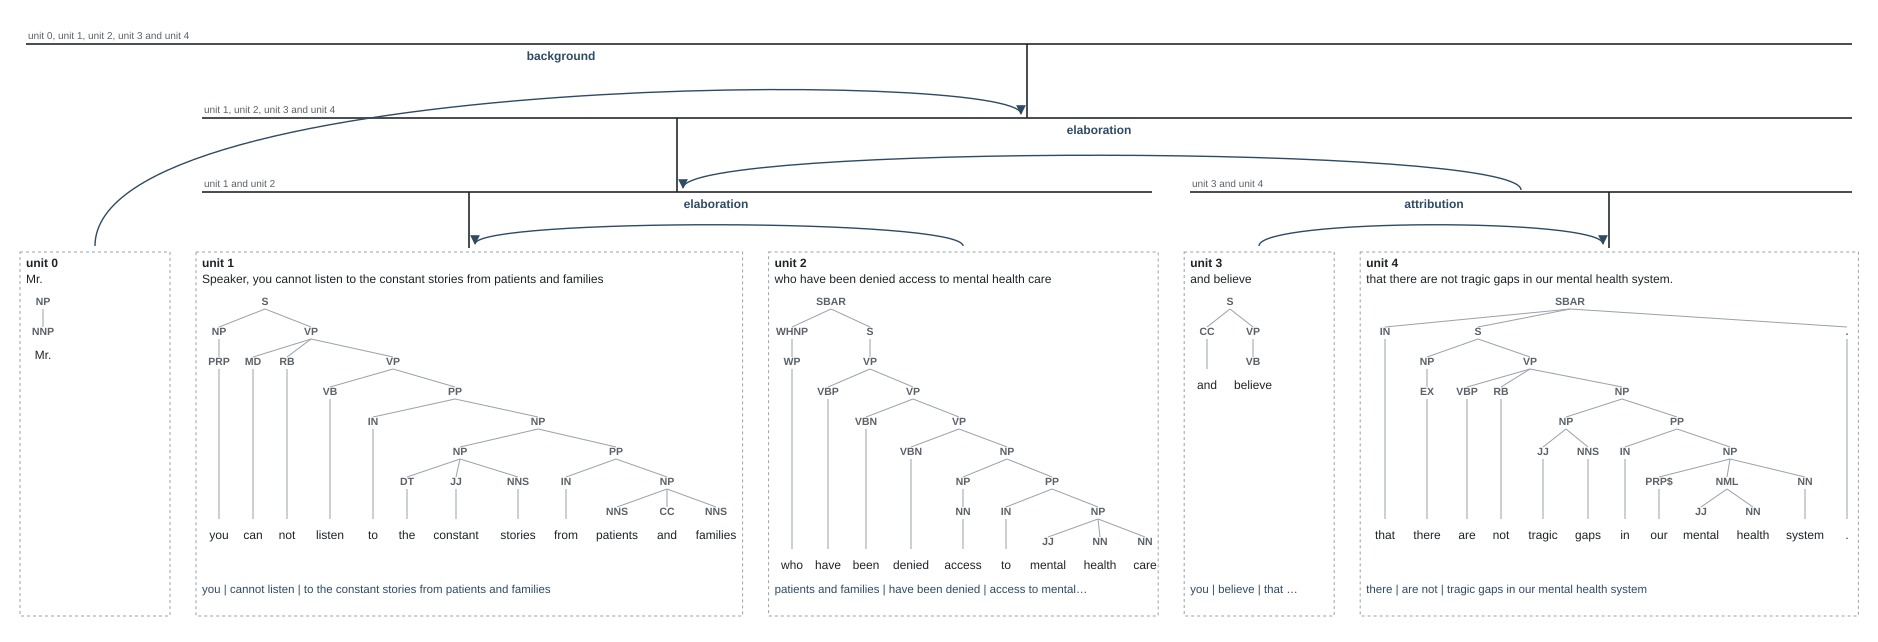


US House  more|US|3: It has been said that there are no losers as it relates to home health care in this bill.


,connection,relation,parser's own label,main part,how it reads
0,unit 0 to unit 1,background,background,unit 0,background; main part unit 0; unit 1 gives background or context for unit 0


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,0,It,has been said,,that there are no losers,its own unit,,,
1,0,there,are,,no losers,its own unit,,,
2,1,it,relates,,to home health care,its own unit,,,


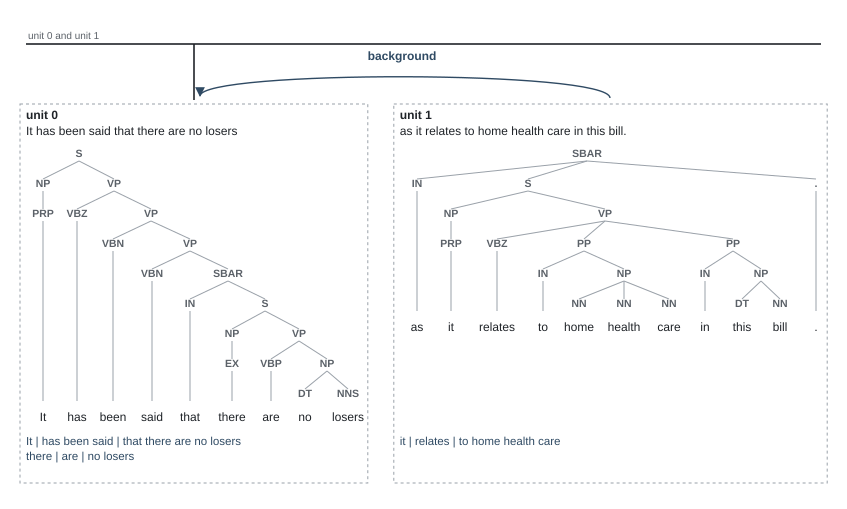


Ontario  more|ON|1: They refuse to invest, when we know it makes economic sense to do so and that it's the right thing to do in terms of health policy in where the public wants to go in receiving their home care services.


,connection,relation,parser's own label,main part,how it reads
0,unit 3 to unit 4,elaboration,elaboration,unit 3,elaboration; main part unit 3; unit 4 adds detail to unit 3
1,unit 2 to unit 3 and unit 4,joint,joint,both,joint; both equally important
2,"unit 1 to unit 2, unit 3 and unit 4",attribution,attribution,"unit 2, unit 3 and unit 4","attribution; main part unit 2, unit 3 and unit 4; unit 1 says who says unit 2, unit 3 ..."
3,"unit 0 to unit 1, unit 2, unit 3 and unit 4",background,background,unit 0,"background; main part unit 0; unit 1, unit 2, unit 3 and unit 4 give background or con..."


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,0,They,refuse to invest,,,its own unit,,,
1,1,we,know,,it makes economic sense to do so and that it's the right thing to do in terms of healt...,its own unit,"discourse: what is said, unit 2, unit 3 and unit 4",,
2,2,it,makes,,economic sense to do so,its own unit,,,
3,2,(unstated),do,to-infinitive,so,an infinitive on the noun before it with no object of its own ('the right thing to do'...,,,
4,3,it,is,,the right thing,its own unit,,,
5,3,(unstated),do,to-infinitive,in terms of health policy,an infinitive on the noun before it with no object of its own ('the right thing to do'...,,,
6,3,the public,wants to go,,,its own unit,,,
7,4,(unstated),receiving,,their home care services,"a gerund after a preposition, on the noun before it ('the formula | for determining .....",,,


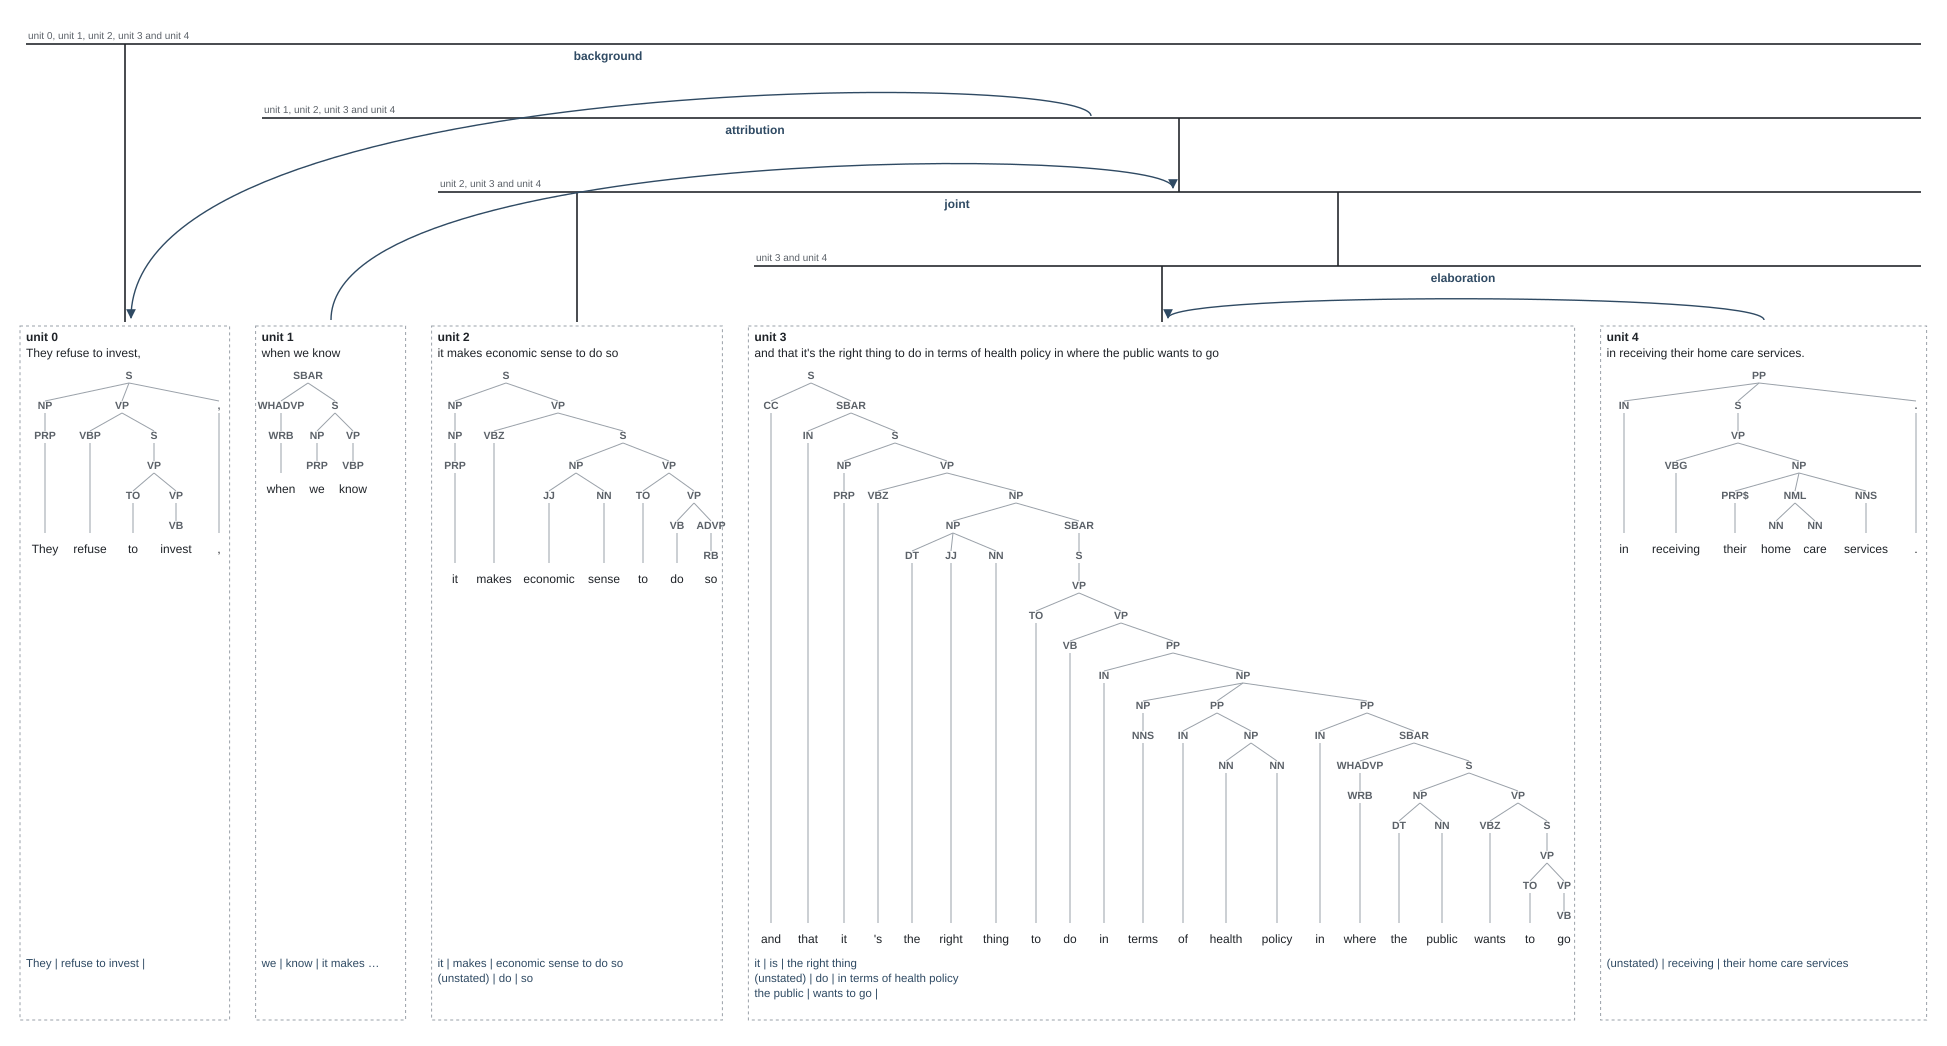


Ontario  more|ON|2: Instead of that, we are going to say, "You can only practise so much at such and such a rate, and then after that we control you." It is a very sad day.


,connection,relation,parser's own label,main part,how it reads
0,unit 1 to unit 2,time-sequence,temporal,both,time-sequence; both equally important
1,unit 0 to unit 1 and unit 2,attribution,attribution,unit 1 and unit 2,attribution; main part unit 1 and unit 2; unit 0 says who says unit 1 and unit 2
2,"unit 0, unit 1 and unit 2 to unit 3",evaluation,evaluation,"unit 0, unit 1 and unit 2","evaluation; main part unit 0, unit 1 and unit 2; unit 3 comments on unit 0, unit 1 and..."


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,0,we,are going to say,,"You can only practise so much at such and such a rate, and then after that we control you",its own unit,,,
1,1,You,can practise,,so much,its own unit,,,
2,2,we,control,,you,unit tree: the subject of the clause the verb sits in,,,
3,3,It,is,,a very sad day,its own unit,,,


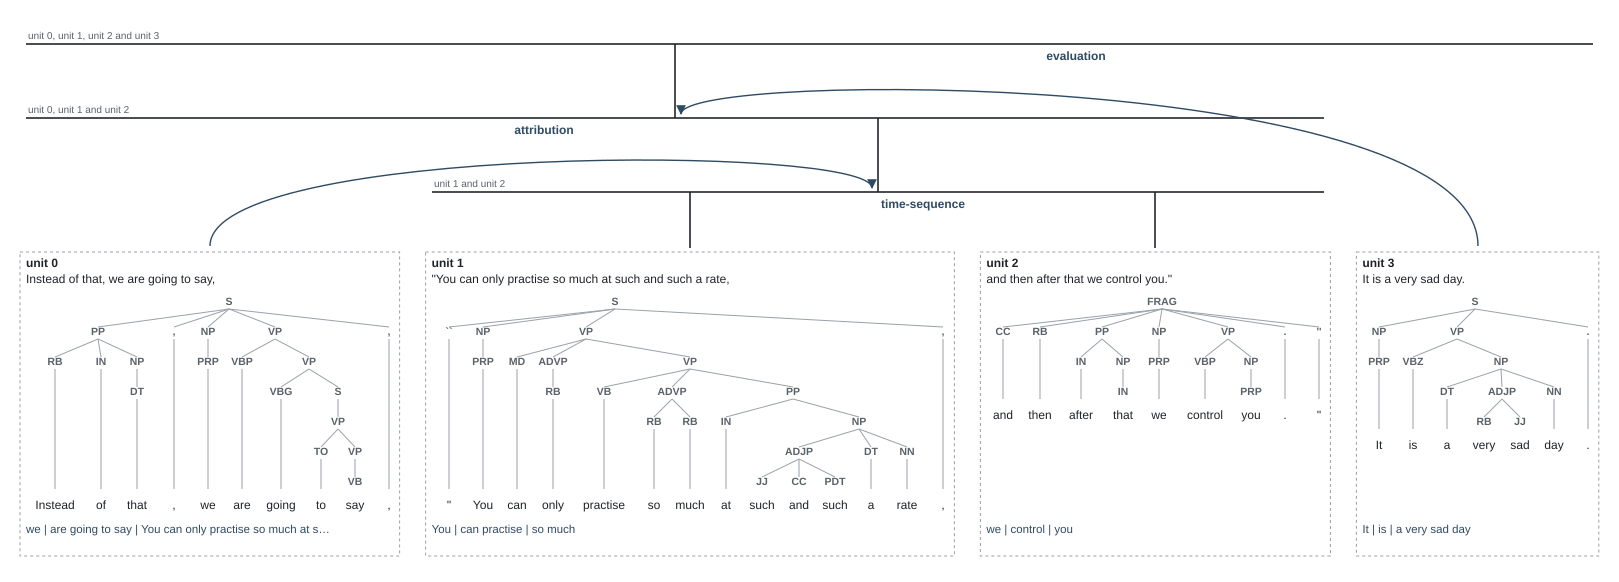


Quebec  more|QC|2: Et pourquoi, dans les deux premiers cas, la municipalité paierait et, dans le troisième cas, elle se verrait conférer le privilège de tout obtenir gratuitement?


,connection,relation,parser's own label,main part,how it reads
0,unit 0 to unit 1,background,frame,unit 0,background; main part unit 0; unit 1 gives background or context for unit 0
1,unit 0 and unit 1 to unit 2,background,frame,unit 0 and unit 1,background; main part unit 0 and unit 1; unit 2 gives background or context for unit 0...
2,unit 4 to unit 5,background,frame,unit 4,background; main part unit 4; unit 5 gives background or context for unit 4
3,unit 3 to unit 4 and unit 5,background,frame,unit 3,background; main part unit 3; unit 4 and unit 5 give background or context for unit 3
4,"unit 0, unit 1 and unit 2 to unit 3, unit 4 and unit 5",joint,continuation,"unit 0, unit 1 and unit 2","joint; main part unit 0, unit 1 and unit 2; unit 3, unit 4 and unit 5 are listed with ..."


""


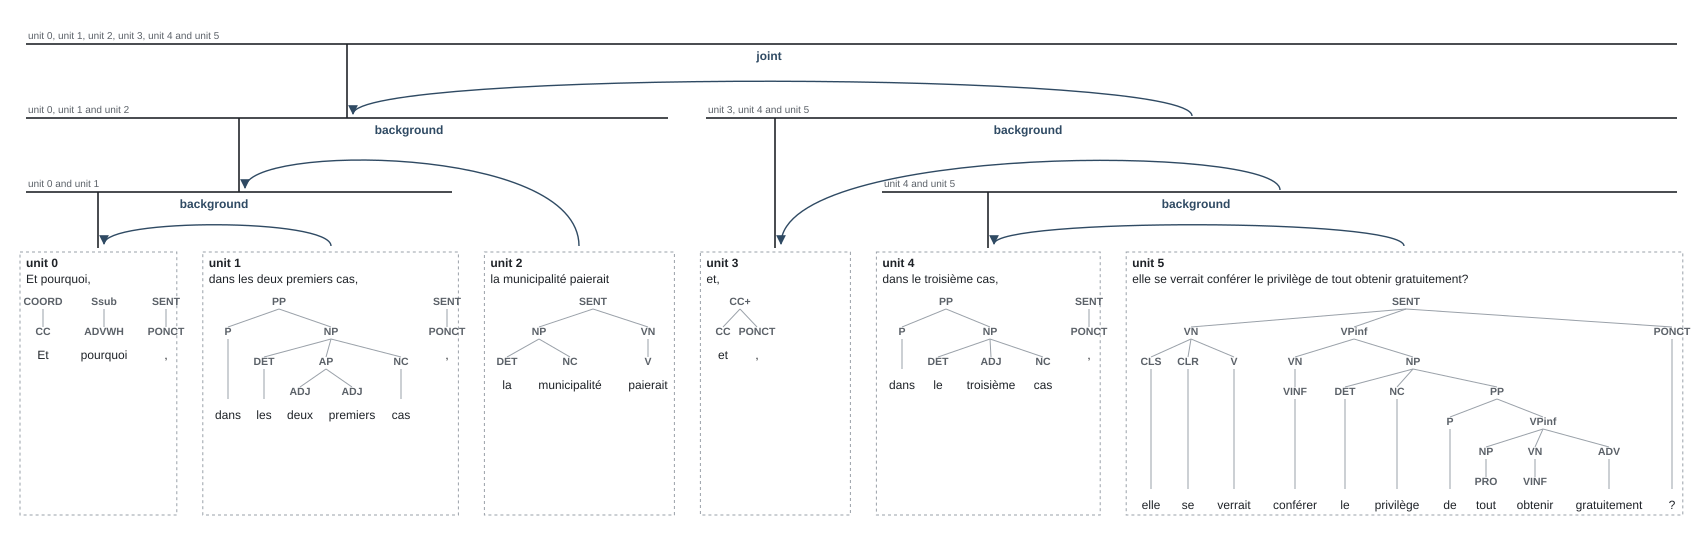


Quebec  more|QC|3: Les nouveaux élus, peu importe de la formation politique, de la nôtre, de la leur, des autres, commencent à comprendre l'importance des débats qu'on a en commission parlementaire, l'importance de l'étude article par article.


,connection,relation,parser's own label,main part,how it reads
0,unit 0 to unit 1,elaboration,e-elaboration,unit 0,elaboration; main part unit 0; unit 1 adds detail to unit 0
1,unit 0 and unit 1 to unit 2,same-unit,same-unit,both,same-unit; both equally important
2,"unit 0, unit 1 and unit 2 to unit 3",joint,continuation,"unit 0, unit 1 and unit 2","joint; main part unit 0, unit 1 and unit 2; unit 3 is listed with unit 0, unit 1 and u..."


,unit,subject,verb,verb form,object,where the subject came from,object from,context,that =
0,2,Les nouveaux élus,commencent à comprendre,,l'importance des débats,unit 0 (same-unit: the sentence goes on after an insertion),,,
1,2,on,a,,débats (qu'),its own unit,,,


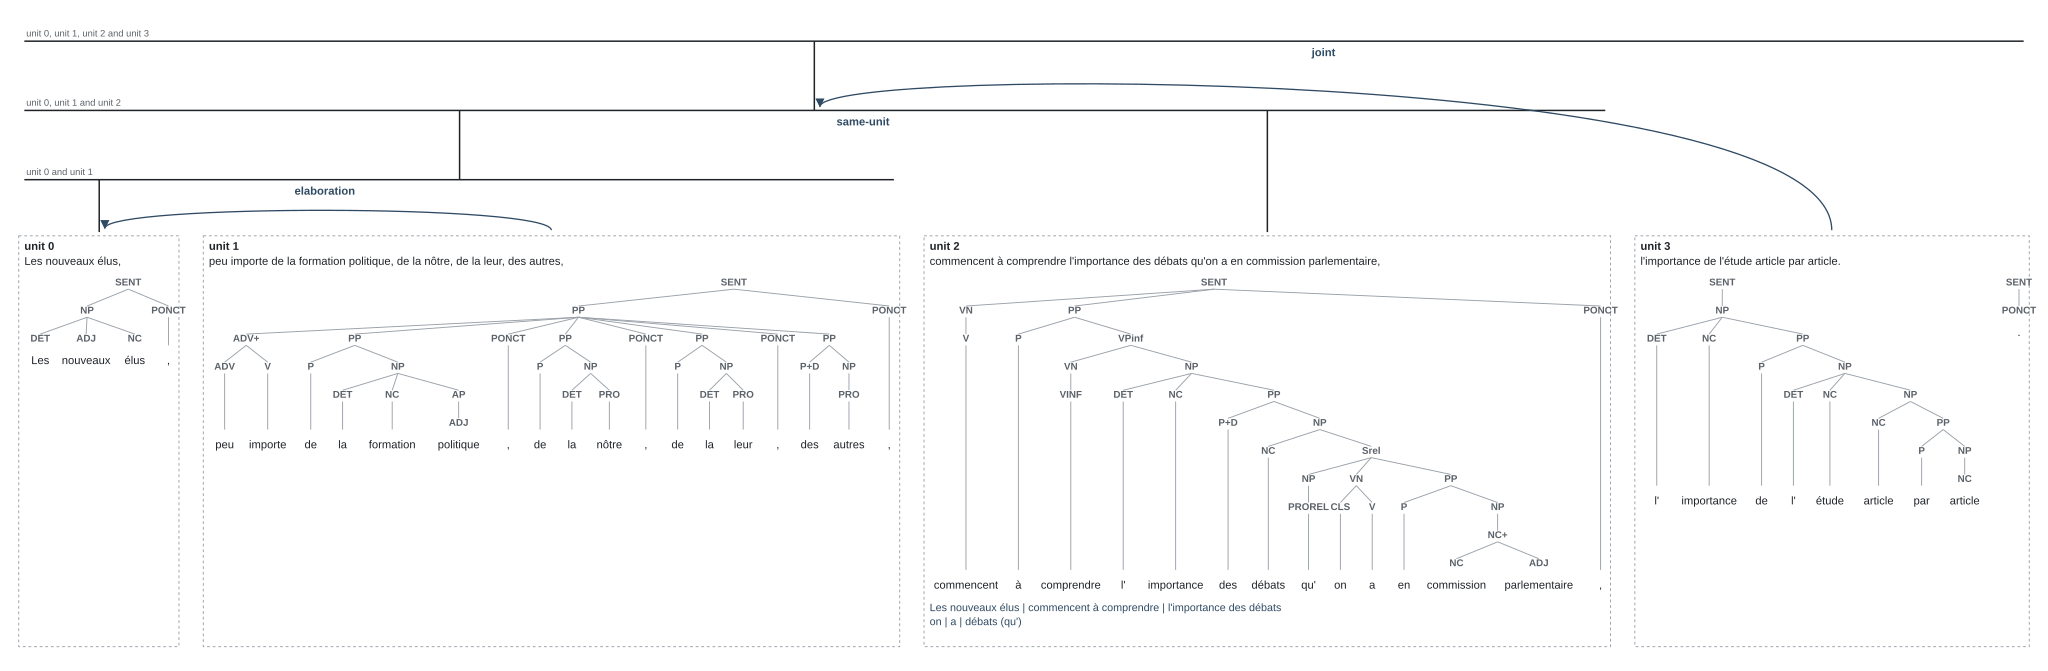

In [7]:
# two figures per legislature
shown = collections.Counter()
for n, x in RECS.items():
    if shown[x["legislature"]] < 2 and 2 <= len(x["units"]) <= 6:
        shown[x["legislature"]] += 1
        print(f"\n{x['legislature']}  {n}: {x['text']}")
        display(relation_table(x)); display(lines_table(x))
        display(SVG(D.figure(x)))

## Part 5. The data structure, with every step

One record per sentence, written to `outputs/edu/discourse_first_records.json`, and three flat tables for looking things up in DBpedia. Every record keeps the discourse parse as it came out of the parser, the units, each unit's tree (bracketed and as nested lists), the lines from each unit, where every borrowed subject or object came from, and the connections between units.

In [8]:
SCHEMA = [
 ("n, legislature, sentence_id, lang, text", "which sentence"),
 ("discourse_status", "how the discourse parse ran"),
 ("units[].unit, text, start, end", "step 1: each discourse unit and where it sits in the sentence (characters)"),
 ("units[].tree, units[].tree_nodes", "step 2: the unit's constituency tree, bracketed and as nested lists [label, [children]]"),
 ("units[].lines[]", "step 3 and 4: subject, verb, object read from that unit"),
 ("lines[].subject_from / object_from", "step 4: blank when it came from the unit itself; otherwise which unit and which relation it came through"),
 ("lines[].refers_to", "step 4: what 'that' / 'ça' stands for (the text of the units it points to)"),
 ("lines[].context", "step 4: a unit with no clause of its own that frames this line ('L'an dernier')"),
 ("lines[].negated, kind, how", "negation; stated or embedded; which tree rule gave the line"),
 ("relations[]", "the discourse parse's relations: left and right units, relation, nuclearity, main part"),
 ("connections[]", "the same relations written as 'unit 0 and unit 1 to unit 2', with the text on each side"),
]
display(pd.DataFrame(SCHEMA, columns=["field", "what it holds"]))

ALL = dict(RECS)
for n in ("sample|1", "test|A8|fr"):
    r = BY_N[n]; t, _ = step2(r); ALL.setdefault(n, dict(run(r, t), legislature=legislature(r), sentence_id=r.get("sentence_id")))
json.dump({"design": "discourse first, then a constituency tree per unit (Oct 22)", "made": time.strftime("%Y-%m-%d %H:%M"),
           "trees": "parsed now" if LIVE else src, "rows": list(ALL.values())},
          open(OUTDIR / "discourse_first_records.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

flat, conns = [], []
for n, x in ALL.items():
    for l in x["lines"]:
        flat.append({"n": n, "legislature": x.get("legislature"), "lang": x["lang"], "unit": l["unit"],
                     "unit text": x["units"][l["unit"]]["text"], "subject": l["subject"], "verb": l["verb"], "object": l["object"],
                     "negated": l["negated"], "kind": l["kind"], "subject from": l.get("subject_from") or "",
                     "object from": l.get("object_from") or "", "that =": l.get("refers_to") or "", "context": "; ".join(l.get("context") or [])})
    for c in x["connections"]:
        conns.append({"n": n, "legislature": x.get("legislature"), "connection": c["from"] + " to " + c["to"], "relation": c["relation"], "parser's own label": c.get("parser_label", ""),
                      "main part": c["main"], "from text": c["from_text"], "to text": c["to_text"]})
DL = pd.DataFrame(flat); DC_ = pd.DataFrame(conns)
DL.to_csv(OUTDIR / "discourse_first_lines.csv", index=False); DC_.to_csv(OUTDIR / "discourse_first_connections.csv", index=False)

# the noun phrases to look up in DBpedia: every subject and object, with how often it comes up
def clean_np(s):
    s = re.sub(r"\(inh\)|\(unstated\)", "", s or "").strip(" ,.;:«»“”\"")
    return s if s and s.lower() not in E.DEMONSTR | {"i", "we", "you", "he", "she", "they", "il", "elle", "nous", "vous", "ils", "elles", "je", "on"} else ""
nouns = collections.Counter()
for l in flat:
    for k in ("subject", "object"):
        if clean_np(l[k]):
            nouns[(clean_np(l[k]), l["lang"], k)] += 1
DN = pd.DataFrame([{"noun phrase": a, "lang": b, "as": c, "times": v} for (a, b, c), v in nouns.most_common()])
DN.to_csv(OUTDIR / "discourse_first_noun_phrases.csv", index=False)
print(f"wrote {OUTDIR / 'discourse_first_records.json'} ({len(ALL)} sentences)")
print(f"      {OUTDIR / 'discourse_first_lines.csv'} ({len(DL)} lines)")
print(f"      {OUTDIR / 'discourse_first_connections.csv'} ({len(DC_)} connections)")
print(f"      {OUTDIR / 'discourse_first_noun_phrases.csv'} ({len(DN)} noun phrases to look up)")
print("\nOne record, the English sentence from the meeting (trees shortened):")
rec = copy.deepcopy(ALL["sample|1"])
for u in rec["units"]:
    u["tree_nodes"] = "[...]"; u["tree"] = [t[:80] + "..." for t in u["tree"]]
print(json.dumps({k: rec[k] for k in ("n", "lang", "text", "units", "connections")}, ensure_ascii=False, indent=1)[:4000])

,field,what it holds
0,"n, legislature, sentence_id, lang, text",which sentence
1,discourse_status,how the discourse parse ran
2,"units[].unit, text, start, end",step 1: each discourse unit and where it sits in the sentence (characters)
3,"units[].tree, units[].tree_nodes","step 2: the unit's constituency tree, bracketed and as nested lists [label, [children]]"
4,units[].lines[],"step 3 and 4: subject, verb, object read from that unit"
5,lines[].subject_from / object_from,step 4: blank when it came from the unit itself; otherwise which unit and which relati...
6,lines[].refers_to,step 4: what 'that' / 'ça' stands for (the text of the units it points to)
7,lines[].context,step 4: a unit with no clause of its own that frames this line ('L'an dernier')
8,"lines[].negated, kind, how",negation; stated or embedded; which tree rule gave the line
9,relations[],"the discourse parse's relations: left and right units, relation, nuclearity, main part"


wrote /Users/caprice/MiscellaneousProjects/legislative-health-factuality/outputs/edu/discourse_first_records.json (62 sentences)
      /Users/caprice/MiscellaneousProjects/legislative-health-factuality/outputs/edu/discourse_first_lines.csv (195 lines)
      /Users/caprice/MiscellaneousProjects/legislative-health-factuality/outputs/edu/discourse_first_connections.csv (138 connections)
      /Users/caprice/MiscellaneousProjects/legislative-health-factuality/outputs/edu/discourse_first_noun_phrases.csv (235 noun phrases to look up)

One record, the English sentence from the meeting (trees shortened):
{
 "n": "sample|1",
 "lang": "en",
 "text": "A small hardware store in an AHP would be joining an association, sending their premiums not to themselves but off to others, and that is why we need the check.",
 "units": [
  {
   "unit": 0,
   "text": "A small hardware store in an AHP would be joining an association,",
   "start": 0,
   "end": 65,
   "tree": [
    "(ROOT (S (NP (NP (DT A) (JJ sm

## Part 6. How the design was kept

Checks that the notebook does what was agreed, and nothing else. Each prints PASS or FAIL.

In [9]:
RESULTS = []
def check(name, ok, detail=""):
    RESULTS.append((name, "PASS" if ok else "FAIL"))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f"\n        {detail}" if detail and not ok else ""))

TREES = {r["n"]: step2(r)[0] for r in ROWS}
OUT = {r["n"]: run(r, TREES[r["n"]]) for r in ROWS}

# every rule and key file comes from scripts/v6, including the French rules, which load only when first needed
import const_fr as _cf
WRONG = {m: sys.modules[m].__file__ for m in RULE_MODULES if Path(sys.modules[m].__file__).resolve().parent != RULES.resolve()}
check("every rule and key file is the scripts/v6 copy (" + ", ".join(RULE_MODULES) + ")", not WRONG, WRONG)

# no dependency parse: the saved dependency parses are removed and every output stays the same
no_deps = {r["n"]: run({k: v for k, v in r.items() if not k.startswith("deps")}, TREES[r["n"]]) for r in ROWS}
diff = [n for n in OUT if json.dumps(OUT[n], sort_keys=True) != json.dumps(no_deps[n], sort_keys=True)]
check("no dependency parse is used (outputs identical with the dependency parses deleted)", not diff, diff[:5])

# no whole-sentence constituency tree: the sentence's tree is removed and every output stays the same
no_tree = {r["n"]: run(dict(r, trees=[]), TREES[r["n"]]) for r in ROWS}
diff = [n for n in OUT if json.dumps(OUT[n]["lines"], sort_keys=True) != json.dumps(no_tree[n]["lines"], sort_keys=True)]
check("the sentence's own tree is not read (lines identical with it deleted)", not diff, diff[:5])

# the discourse parse comes first: every unit's tree holds exactly that unit's words, in order
bad = []
for n, x in OUT.items():
    for u in x["units"]:
        words = re.sub(r"[^\w]", "", "".join(w for t in u["tree_nodes"] for w in E.leaves_of(t))).lower()
        if words != re.sub(r"[^\w]", "", u["text"]).lower() and not (words and words in re.sub(r"[^\w]", "", u["text"]).lower()):
            bad.append((n, u["unit"]))
check("each unit's tree holds that unit's words and nothing else", not bad, bad[:5])

# connections within a unit: a line's verb is in its own unit
bad = [(n, l["unit"], l["verb"]) for n, x in OUT.items() for l in x["lines"]
       if not l.get("implied_verb") and not all(w in x["units"][l["unit"]]["text"].lower().replace("’", "'") for w in E.tokens((l.get("verb_as_written") or l["verb"]).lower().replace("’", "'")) if w)]
check("every verb is in its own unit", not bad, bad[:5])
bad = [(n, l["unit"], l["verb"]) for n, x in OUT.items() for l in x["lines"] if l.get("implied_verb") and l["verb"] != "is (apposition)"]
check("the only verb not written in the text is the implied 'is' of an apposition", not bad, bad[:5])

# connections between units: anything taken from another unit says which one and through which relation
bad = []
for n, x in OUT.items():
    for l in x["lines"]:
        s = re.sub(r"[^\w]", "", l["subject"].replace("(inh)", "").lower())
        if s and s != "unstated" and s not in re.sub(r"[^\w]", "", x["units"][l["unit"]]["text"].lower()) and not l.get("subject_from"):
            bad.append((n, l["unit"], l["subject"]))
check("every subject taken from another unit is labelled with where it came from", not bad, bad[:5])

# the agreed notation
reads = [c["from"] + " to " + c["to"] for x in OUT.values() for c in x["connections"]]
check("relations are written 'unit 0 and unit 1 to unit 2'", all(re.fullmatch(r"unit \d+((, unit \d+)* and unit \d+)? to unit \d+((, unit \d+)* and unit \d+)?", r) for r in reads)
      and not any(re.search(r"units \d", c["reads"]) for x in OUT.values() for c in x["connections"]), [r for r in reads if "units" in r][:3])

# well formed relations, and the same result twice
bad = [(n, r["reads"]) for n, x in OUT.items() for r in x["relations"]
       if not (0 <= r["left"][0] <= r["left"][1] < r["right"][0] <= r["right"][1] < len(x["units"]) and r["left"][1] + 1 == r["right"][0])]
check("discourse relations join neighbouring spans", not bad, bad[:5])
again = {r["n"]: run(r, TREES[r["n"]]) for r in ROWS}
check("the same input gives the same output", all(json.dumps(OUT[n], sort_keys=True) == json.dumps(again[n], sort_keys=True) for n in OUT))

[PASS] every rule and key file is the scripts/v6 copy (preds, lexicon, const_fr, combine_lib, frames, parity_score, full, compare3, gold, gold2, gold_heldout, parallel_tests, edu_pipeline, edu_draw)
[PASS] no dependency parse is used (outputs identical with the dependency parses deleted)
[PASS] the sentence's own tree is not read (lines identical with it deleted)
[PASS] each unit's tree holds that unit's words and nothing else
[PASS] every verb is in its own unit
[PASS] the only verb not written in the text is the implied 'is' of an apposition
[PASS] every subject taken from another unit is labelled with where it came from
[PASS] relations are written 'unit 0 and unit 1 to unit 2'
[PASS] discourse relations join neighbouring spans
[PASS] the same input gives the same output


### What the meeting said each example should give

In [10]:
def L(rec):
    return [(l["unit"], l["subject"], l["verb"], l["object"]) for l in rec["lines"]]
en = OUT["sample|1"]; fr = OUT["test|A8|fr"]
check("EN unit 0: A small hardware store in an AHP | would be joining | an association",
      (0, "A small hardware store in an AHP", "would be joining", "an association") in L(en), L(en))
u1 = [l for l in en["lines"] if l["unit"] == 1]
check("EN unit 1 takes the subject of unit 0 through the elaboration: ... | sending | their premiums",
      bool(u1) and u1[0]["subject"] == "A small hardware store in an AHP" and u1[0]["verb"] == "sending" and "elaboration" in u1[0]["subject_from"], u1)
th = [l for l in en["lines"] if l["subject"].lower() == "that"]
check("EN unit 2: 'that' is unit 0 and unit 1 together", bool(th) and th[0].get("refers_to", "").startswith("unit 0 and unit 1:"), th)
check("EN unit 2: we | need | the check", (2, "we", "need", "the check") in L(en), L(en))
check("EN connection: unit 0 and unit 1 to unit 2, explanation, unit 2 the main part",
      any(c["from"] == "unit 0 and unit 1" and c["to"] == "unit 2" and c["relation"] == "explanation" and c["main"] == "unit 2" for c in en["connections"]), en["connections"])
check("EN connection: unit 0 to unit 1, elaboration", any(c["from"] == "unit 0" and c["to"] == "unit 1" and c["relation"] == "elaboration" for c in en["connections"]))
check("FR unit 1 and unit 2 are a contrast", any(c["from"] == "unit 1" and c["to"] == "unit 2" and c["relation"] == "contrast" for c in fr["connections"]), fr["connections"])
check("FR unit 0 (L'an dernier) frames unit 1 and unit 2", any(c["from"] == "unit 0" and c["to"] == "unit 1 and unit 2" and c["relation"] == "background" for c in fr["connections"]))
check("FR: la Chambre | a adopté | un projet de loi identique au projet de loi 5",
      (1, "la Chambre", "a adopté", "un projet de loi identique au projet de loi 5") in L(fr), L(fr))
check("FR: le Sénat | a refusé d'agir", (2, "le Sénat", "a refusé d'agir", "") in L(fr), L(fr))
check("FR: both facts carry 'L'an dernier' as their frame", all(any(c.startswith("L'an dernier") for c in l.get("context", [])) for l in fr["lines"]), fr["lines"])

[PASS] EN unit 0: A small hardware store in an AHP | would be joining | an association
[PASS] EN unit 1 takes the subject of unit 0 through the elaboration: ... | sending | their premiums
[PASS] EN unit 2: 'that' is unit 0 and unit 1 together
[PASS] EN unit 2: we | need | the check
[PASS] EN connection: unit 0 and unit 1 to unit 2, explanation, unit 2 the main part
[PASS] EN connection: unit 0 to unit 1, elaboration
[PASS] FR unit 1 and unit 2 are a contrast
[PASS] FR unit 0 (L'an dernier) frames unit 1 and unit 2
[PASS] FR: la Chambre | a adopté | un projet de loi identique au projet de loi 5
[PASS] FR: le Sénat | a refusé d'agir
[PASS] FR: both facts carry 'L'an dernier' as their frame


### Each rule on its own

Small cases with a known answer. Trees are written in the bracket form the parsers give. The rules marked *discourse* are the connections between units (step 4); the others read one unit's tree (step 3).

In [11]:
def T(s):
    def conv(n):
        return n if isinstance(n, str) else [n[0], [conv(k) for k in n[1]]]
    return conv(P.parse_tree(s))

def leaf_path(tree, word, nth=0):
    ps = E.paths([tree]); ws = E.leaves_of(tree)
    return ps[[i for i, w in enumerate(ws) if w == word][nth]]

def lines_of(n):
    return [(l["subject"], l["verb"], l["object"]) for l in OUT[n]["lines"]]

# step 3, inside one unit's tree
check("unit tree: VP holding only (CC, VP) after cutting is merged",
      E.bracket(E.collapse(T("(VP (CC and) (VP (VBP rise) (PP (IN in) (NP (NN support)))))"))) == "(VP (CC and) (VBP rise) (PP (IN in) (NP (NN support))))")
check("unit tree: 'Mr. Speaker,' is someone addressed, not the subject",
      E.bracket(E.drop_address(T("(S (NP (NNP Mr.) (NNP Speaker)) (, ,) (NP (PRP I)) (VP (VBP thank) (NP (DT the) (NN gentleman))))"))) == "(S (NP (PRP I)) (VP (VBP thank) (NP (DT the) (NN gentleman))))")
check("unit tree (French): a clause inside COORD is read as a clause",
      E.bracket(E.unwrap_coord(T("(SENT (COORD (CC mais) (NP (DET le) (NPP Sénat)) (VN (V a) (VPP refusé))))"))) == "(SENT (CC mais) (NP (DET le) (NPP Sénat)) (VN (V a) (VPP refusé)))")
t = T("(ROOT (S (NP (DT The) (NN minister)) (VP (VBD urged) (NP (DT the) (NNS doctors)) (S (VP (TO to) (VP (VB accept) (NP (DT the) (NN deal))))))))")
check("unit tree: urged the doctors to accept -> the doctors accept", E.subject_from_tree(leaf_path(t, "accept"), "en")[0] == "the doctors")
t = T("(ROOT (S (NP (DT The) (NNP Senate)) (VP (VBD refused) (S (VP (TO to) (VP (VB act)))))))")
check("unit tree: The Senate refused to act -> the Senate acts", E.subject_from_tree(leaf_path(t, "act"), "en")[0] == "The Senate")
t = T("(ROOT (S (NP (DT The) (NN government)) (VP (VBD cut) (NP (NNS taxes)) (S (VP (TO to) (VP (VB help) (NP (NNS families))))))))")
check("unit tree: cut taxes to help families -> the government helps (purpose, not 'urge X to')", E.subject_from_tree(leaf_path(t, "help"), "en")[0] == "The government")
t = T("(TOP (SENT (NP (DET Le) (NC ministre)) (VN (V a) (VPP exhorté)) (NP (DET les) (NC médecins)) (PP (P à) (VPinf (VN (VINF accepter)) (NP (DET l') (NC entente))))))")
check("unit tree (French): a exhorté les médecins à accepter -> les médecins", E.subject_from_tree(leaf_path(t, "accepter"), "fr")[0] == "les médecins")
ln = {"verb": "ne pourra congédier", "negated": False}; E.fix_verb(ln, "le gouvernement ne pourra pas congédier les gens")
check("unit text: 'ne ... pas' stays in the verb and marks negation", (ln["verb"], ln["negated"]) == ("ne pourra pas congédier", True))
check("unit tree: refused to act is one verb (sample|6)", [l[1] for l in lines_of("sample|6")] == ["passed", "refused to act"], lines_of("sample|6"))
check("unit: a question is not a claim (test|A11|en)", lines_of("test|A11|en") == [], lines_of("test|A11|en"))

# step 4, through the discourse parse
check("discourse: 'who went underground' -> miners (the noun phrase of the unit it elaborates; sample|43)",
      ("miners", "went", "underground") in lines_of("sample|43"), lines_of("sample|43"))
check("discourse: 'miners | who ... | were exposed' -> miners (same-unit; sample|43)",
      any(l[0] == "miners" and l[1] == "were exposed" for l in lines_of("sample|43")), lines_of("sample|43"))
check("discourse: 'women | donating fetal tissue' (no comma) -> women (sample|2)",
      any(l[0] == "women" and l[1] == "donating" for l in lines_of("sample|2")), lines_of("sample|2"))
check("discourse: 'a store ..., | sending' (comma) -> the store, not the association (sample|1)",
      any(l[0].startswith("A small hardware store") and l[1] == "sending" for l in lines_of("sample|1")))
check("discourse: 'The report also recommends' | 'that ...' -> the object is what unit 2 says (attribution; sample|38)",
      any(l[1] == "recommends" and l[2].startswith("that the Ministry") for l in lines_of("sample|38")), lines_of("sample|38"))
check("discourse: 'repeal these ... rights' | 'that were extended' -> these health care rights and protections (sample|17)",
      any(l[0] == "these health care rights and protections" and l[1] == "were extended" for l in lines_of("sample|17")), lines_of("sample|17"))
check("discourse: 'cut taxes' | 'to help families' -> the government (purpose; test|E7|en)",
      any(l[0] == "The government" and "help" in l[1] for l in lines_of("test|E7|en")), lines_of("test|E7|en"))
check("discourse: a verbless unit is context only for background-type relations (no context in sample|37)",
      not any(l.get("context") for l in OUT["sample|37"]["lines"]))

[PASS] unit tree: VP holding only (CC, VP) after cutting is merged
[PASS] unit tree: 'Mr. Speaker,' is someone addressed, not the subject
[PASS] unit tree (French): a clause inside COORD is read as a clause
[PASS] unit tree: urged the doctors to accept -> the doctors accept
[PASS] unit tree: The Senate refused to act -> the Senate acts
[PASS] unit tree: cut taxes to help families -> the government helps (purpose, not 'urge X to')
[PASS] unit tree (French): a exhorté les médecins à accepter -> les médecins
[PASS] unit text: 'ne ... pas' stays in the verb and marks negation
[PASS] unit tree: refused to act is one verb (sample|6)
[PASS] unit: a question is not a claim (test|A11|en)
[PASS] discourse: 'who went underground' -> miners (the noun phrase of the unit it elaborates; sample|43)
[PASS] discourse: 'miners | who ... | were exposed' -> miners (same-unit; sample|43)
[PASS] discourse: 'women | donating fetal tissue' (no comma) -> women (sample|2)
[PASS] discourse: 'a store ..., | sendin

### The fixes from the Oct 26 runs

Each case below is one problem found in the runs on the Mac, with the tree written out in the shape the Mac's parser gave. Each one failed before its fix; the controls (a subject that only looks like a time, 'that' still pointing back, purpose still working, 'the fact that ...', 'measures to help us', a real 'it') passed before and after.

- a time is not the subject ('Last year the House passed'); I'm -> am; cannot as written
- 'it' never points to units; 'that' / 'ça' point back only, never forward; 'c'' / 'ce' only for explanation, evaluation, cause
- who / which / qui: the noun it hangs on; never a question word ('qu'est-ce qui'); 'which is why' and an evaluating 'which' stand for the whole clause
- object relatives: 'the resources | that they need', 'le menu législatif | qu'on a fait passer'; not 'the fact | that ...'
- infinitives: 'It is time | to stop', 'the right thing to do', 'economic sense to do so' have no stated doer; 'measures to help us', 'a base | to offset the portion' do
- a unit that is only a verb ('said', 'prévoit', 'are the people') gets a line for the discourse parse to fill; a FRAG with a subject is a clause
- a borrowed subject comes from the main part of the earlier span, the nearest clause in it, or the clause doing the saying in an attribution; never the empty 'It' of 'It is time'
- an adverb is not the object when a phrase follows it ('is also a moral obligation'); 'ne reçoivent plus | ce service'; 'mess up | that'
- French: 'n'aient pas', 'Il | y a', 'n'est pas' as written; 'peu importe' and 'what have you' are not claims; 'Mme la Présidente' is not an object
- a question sentence gives no claims; 'If passed,' stays context; 'Mr. Speaker,' is never context
- new sentences leave out quoted bill text
- round 5: what is said, read from the words ('a dit | que ...', 'a dit : « ... »', 'décidera | si ...'), because the French discourse model marks the sayer as the main part and the English one marks what is said; a short aside ('qui, | je constate, |') says nothing
- round 5: appositions in a unit's own tree ('Jean Martin, the health minister,') and across two units joined by elaboration ('Jean Martin, | le ministre de la Santé,'); never a form of address ('Bill 87, Speaker,') or a speaker label ('M. Brassard: | ...')
- round 5: 'by closing clinics' when the unit's parser read 'closing' as a noun; 'jusqu'à ce que' is a conjunction, not an object 'ce (que)'
- round 5: an English to-infinitive is written as the bare verb ('accept', 'stop') and marked to-infinitive in its own column, so it matches the key word for word

In [12]:
def row_of(text, lang, units, rels):
    "A sentence typed in, with its units and relations given, to test one rule on trees written out by hand."
    edus, pos = [], 0
    for u_ in units:
        i = text.index(u_, pos); edus.append({"text": u_, "start": i, "end": i + len(u_)}); pos = i + len(u_)
    return {"n": "t", "set": "typed", "lang": lang, "text": text, "trees": [], "disc_native": {"edus": edus, "relations": rels}}

def show(rec):
    return [(l["unit"], l["subject"], l["verb"], l["object"], l.get("subject_from", ""), l.get("context"), l.get("refers_to"), bool(l.get("infinitive"))) for l in rec["lines"]]

def process(r, trees):
    return run(r, trees)




# 5. a time as subject, in the two shapes the parser can give for the unit alone
txt = "Last year the House passed legislation identical to H.R. 5, but the Senate refused to act."
rels = [{"left": [0, 0], "right": [1, 1], "relation": "adversative", "nuclearity": "NN"}]
senate = "(ROOT (S (CC but) (NP (DT the) (NNP Senate)) (VP (VBD refused) (S (VP (TO to) (VP (VB act))))) (. .)))"
for shape in ["(ROOT (S (NP (JJ Last) (NN year)) (NP (DT the) (NNP House)) (VP (VBD passed) (NP (NP (NN legislation)) (ADJP (JJ identical) (PP (IN to) (NP (NNP H.R.) (CD 5)))))) (, ,)))",
              "(ROOT (S (NP (NP (JJ Last) (NN year)) (NP (DT the) (NNP House))) (VP (VBD passed) (NP (NP (NN legislation)) (ADJP (JJ identical) (PP (IN to) (NP (NNP H.R.) (CD 5)))))) (, ,)))"]:
    r = row_of(txt, "en", ["Last year the House passed legislation identical to H.R. 5,", "but the Senate refused to act."], rels)
    L = show(process(r, [[T(shape)], [T(senate)]]))
    check("time is not the subject: " + shape[12:60], L[0][1] == "the House" and L[0][2] == "passed" and any("Last year" in c for c in (L[0][5] or [])), L)
r = row_of("The year of the budget was hard.", "en", ["The year of the budget was hard."], [])
L = show(process(r, [[T("(ROOT (S (NP (NP (DT The) (NN year)) (PP (IN of) (NP (DT the) (NN budget)))) (VP (VBD was) (ADJP (JJ hard))) (. .)))")]]))
check("a noun phrase about a year is still a subject", L[0][1] == "The year of the budget", L)
r = row_of("Last year was hard.", "en", ["Last year was hard."], [])
L = show(process(r, [[T("(ROOT (S (NP (JJ Last) (NN year)) (VP (VBD was) (ADJP (JJ hard))) (. .)))")]]))
check("'Last year was hard': a time alone before the verb stays the subject", L[0][1] == "Last year", L)
r = row_of("L'an dernier la Chambre a adopté le projet de loi.", "fr", ["L'an dernier la Chambre a adopté le projet de loi."], [])
L = show(process(r, [[T("(TOP (SENT (NP (DET L') (NC an) (AP (ADJ dernier))) (NP (DET la) (NC Chambre)) (VN (V a) (VPP adopté)) (NP (DET le) (NC+ (NC projet) (P de) (NC loi))) (PONCT .)))")]]))
check("French: L'an dernier is not the subject", L and L[0][1] == "la Chambre", L)

# 2. contractions
r = row_of("I'm sure up north I can give you examples.", "en", ["I'm sure up north I can give you examples."], [])
rec = process(r, [[T("(ROOT (S (S (NP (PRP I)) (VP (VBP 'm) (ADJP (JJ sure)) (ADVP (RB up) (RB north)))) (S (NP (PRP I)) (VP (MD can) (VP (VB give) (NP (PRP you)) (NP (NNS examples))))) (. .)))")]])
L = show(rec)
check("I'm: the verb is 'am', the form as written kept", L[0][2] == "am" and rec["lines"][0].get("verb_as_written", "").replace("’", "'") in ("'m", "m"), L)
r = row_of("We're cutting the program.", "en", ["We're cutting the program."], [])
L = show(process(r, [[T("(ROOT (S (NP (PRP We)) (VP (VBP 're) (VP (VBG cutting) (NP (DT the) (NN program)))) (. .)))")]]))
check("We're cutting: are cutting", L[0][2] == "are cutting", L)

# 3. 'it' does not point to units
r = row_of("Republicans say it is about cost containment.", "en", ["Republicans say", "it is about cost containment."],
        [{"left": [0, 0], "right": [1, 1], "relation": "attribution", "nuclearity": "SN"}])
L = show(process(r, [[T("(ROOT (S (NP (NNPS Republicans)) (VP (VBP say))))")],
                       [T("(ROOT (S (NP (PRP it)) (VP (VBZ is) (PP (IN about) (NP (NN cost) (NN containment)))) (. .)))")]]))
check("'it' stays 'it' and does not point to 'Republicans say'", L[1][1] == "it" and not L[1][6] and "points" not in (L[1][4] or ""), L)
check("'Republicans say': the object is what unit 1 says", L[0][3].startswith("it is about cost containment"), L)
r = row_of("We cut taxes, and that is why families are better off.", "en", ["We cut taxes,", "and that is why families are better off."],
        [{"left": [0, 0], "right": [1, 1], "relation": "explanation", "nuclearity": "SN"}])
rec = process(r, [[T("(ROOT (S (NP (PRP We)) (VP (VBD cut) (NP (NNS taxes))) (, ,)))")],
                    [T("(ROOT (S (CC and) (NP (DT that)) (VP (VBZ is) (SBAR (WHADVP (WRB why)) (S (NP (NNS families)) (VP (VBP are) (ADJP (JJR better) (RB off)))))) (. .)))")]])
check("'that' still points to the unit it explains", any((l.get("refers_to") or "").startswith("unit 0:") for l in rec["lines"]), show(rec))

# 1. qui inside one unit, and qui opening a unit
r = row_of("Il y a un dossier qui sera constitué.", "fr", ["Il y a un dossier qui sera constitué."], [])
L = show(process(r, [[T("(TOP (SENT (VN (CLS Il) (CLO y) (V a)) (NP (DET un) (NC dossier) (Srel (NP (PROREL qui)) (VN (V sera) (VPP constitué)))) (PONCT .)))")]]))
check("qui inside the unit -> un dossier", any(l[1] == "un dossier" and "constitu" in l[2] for l in L), L)
r = row_of("Je consens à ce qu'il y ait un dossier qui soit constitué pour moi.", "fr", ["Je consens à ce qu'il y ait un dossier", "qui soit constitué pour moi."],
        [{"left": [0, 0], "right": [1, 1], "relation": "e-elaboration", "nuclearity": "NS"}])
L = show(process(r, [[T("(TOP (SENT (NP (CLS Je)) (VN (V consens)) (PP (P à) (NP (PRO ce) (Ssub (CS qu') (VN (CLS il) (CLO y) (V ait)) (NP (DET un) (NC dossier)))))))")],
                       [T("(TOP (SENT (Srel (NP (PROREL qui)) (VN (V soit) (VPP constitué)) (PP (P pour) (NP (PRO moi)))) (PONCT .)))")]]))
check("qui opening a unit -> un dossier, through the discourse parse", any(l[1] == "un dossier" and "constitu" in l[2] for l in L), L)
r = row_of("The miners who went underground were exposed.", "en", ["The miners who went underground were exposed."], [])
L = show(process(r, [[T("(ROOT (S (NP (NP (DT The) (NNS miners)) (SBAR (WHNP (WP who)) (S (VP (VBD went) (ADVP (RB underground)))))) (VP (VBD were) (VP (VBN exposed))) (. .)))")]]))
check("who inside the unit -> The miners", any(l[1] == "The miners" and l[2] == "went" for l in L), L)

# 4. bill text
check("bill text is left out of new draws", E.is_bill_text("“(A) Employer coverage at time of initial general enrollment period.--In the case of an individual who--"), "")
check("an amending instruction is left out", E.is_bill_text("Section 1862(a) of the Social Security Act is amended by adding at the end the following"), "")
check("a spoken motion is kept", not E.is_bill_text("Mr Eves moves that subsection 19(4) of the bill be struck out and the following substituted therefor"), "")
check("ordinary speech is kept", not any(E.is_bill_text(t) for t in ["I was going to say--", "Republicans say it is about cost containment; I say it is about cost shifting.",
                                                                     "I think -- and I mean this -- we should act.", "Mr. Speaker, I yield myself such time as I may consume."]), "")

# follow-ups found by the regression run
r = row_of("Je veux voir qu'est-ce qui justifie la différence.", "fr", ["Je veux voir qu'est-ce qui justifie la différence."], [])
L = show(process(r, [[T("(TOP (SENT (NP (CLS Je)) (VN (V veux)) (VPinf (VN (VINF voir)) (Ssub (NP (PROWH qu')) (VN (V est)) (NP (PRO -ce) (Srel (NP (PROREL qui)) (VN (V justifie)) (NP (DET la) (NC différence)))))) (PONCT .)))")]]))
check("qu'est-ce qui justifie: qu'est-ce | justifie | la différence, and no 'qu' | est | -ce' line", (0, "qu'est-ce", "justifie", "la différence") in [l[:4] for l in L] and not any(l[1] in ("-ce", "qu'", "sa réponse") for l in L), L)
txt = "It is time to stop playing politics with people's lives."
r = row_of(txt, "en", ["It is time", "to stop playing politics with people's lives."], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}])
L = show(process(r, [[T("(ROOT (S (NP (PRP It)) (VP (VBZ is) (NP (NN time)))))")],
                       [T("(ROOT (S (VP (TO to) (VP (VB stop) (S (VP (VBG playing) (NP (NNS politics)) (PP (IN with) (NP (NP (NNS people) (POS 's)) (NNS lives))))))) (. .)))")]]))
check("It is time | to stop: who stops is not stated (verb 'stop', marked to-infinitive)", any(l[2] == "stop" and l[7] and l[1] == "(unstated)" for l in L), L)
r = row_of("The government cut taxes to help families.", "en", ["The government cut taxes", "to help families."], [{"left": [0, 0], "right": [1, 1], "relation": "purpose", "nuclearity": "NS"}])
L = show(process(r, [[T("(ROOT (S (NP (DT The) (NN government)) (VP (VBD cut) (NP (NNS taxes)))))")], [T("(ROOT (S (VP (TO to) (VP (VB help) (NP (NNS families)))) (. .)))")]]))
check("cut taxes | to help families -> The government", any(l[1] == "The government" and "help" in l[2] for l in L), L)

# round 3: from the second Mac run
txt = "Mr. Dingell's motion asks for the maximum level of mental health coverage that does not drive up the premium costs for others."
r = row_of(txt, "en", ["Mr. Dingell's motion asks for the maximum level of mental health coverage", "that does not drive up the premium costs for others."],
        [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}])
L = show(process(r, [[T("(ROOT (S (NP (NP (NNP Mr.) (NNP Dingell) (POS 's)) (NN motion)) (VP (VBZ asks) (PP (IN for) (NP (NP (DT the) (JJ maximum) (NN level)) (PP (IN of) (NP (NN mental) (NN health) (NN coverage))))))))")],
                       [T("(ROOT (S (NP (DT that)) (VP (VBZ does) (RB not) (VP (VB drive) (PRT (RP up)) (NP (NP (DT the) (NN premium) (NNS costs)) (PP (IN for) (NP (NNS others)))))) (. .)))")]]))
check("a fragment's 'that' tagged DT is still the relative: -> mental health coverage | does not drive up", any("coverage" in l[1] and "drive up" in l[2] for l in L), L)
txt = "Mr. Speaker, you cannot listen to these stories."
r = row_of(txt, "en", ["Mr. Speaker,", "you cannot listen to these stories."], [{"left": [0, 0], "right": [1, 1], "relation": "background", "nuclearity": "SN"}])
L = show(process(r, [[T("(ROOT (NP (NNP Mr.) (NNP Speaker) (, ,)))")], [T("(ROOT (S (NP (PRP you)) (VP (MD can) (RB not) (VP (VB listen) (PP (IN to) (NP (DT these) (NNS stories))))) (. .)))")]]))
check("'Mr. Speaker,' is not context, and 'cannot' is written as in the text", L and not L[0][5] and L[0][2] == "cannot listen", L)
pieces_verb = [(T("(ROOT (S (NP (PRP we)) (VP (VBP control) (NP (PRP you)))))"), [])]
check("a unit with its own subject and verb is a clause; 'If passed,' is not; 'L'an dernier,' is not",
      E.has_clause(pieces_verb) and not E.has_clause([(T("(ROOT (SBAR (IN If) (S (VP (VBN passed))) (, ,)))"), [])])
      and not E.has_clause([(T("(TOP (SENT (NP (DET L') (NC an) (AP (ADJ dernier))) (PONCT ,)))"), [])])
      and E.has_clause([(T("(TOP (SENT (CC et) (VN (CLS elle) (V obtiendrait)) (PONCT ?)))"), [])]), "")
txt = "If passed, the act would provide measures."
r = row_of(txt, "en", ["If passed,", "the act would provide measures."], [{"left": [0, 0], "right": [1, 1], "relation": "condition", "nuclearity": "SN"}])
L = show(process(r, [[T("(ROOT (SBAR (IN If) (S (VP (VBN passed))) (, ,)))")], [T("(ROOT (S (NP (DT the) (NN act)) (VP (MD would) (VP (VB provide) (NP (NNS measures)))) (. .)))")]]))
check("'If passed,' is still context for the claim it conditions", L and any("If passed" in c for c in (L[0][5] or [])), L)
check("has_verb sees a verb; is_address sees 'Mr. Speaker,' and 'M. le Président,'", E.has_verb(pieces_verb) and E.is_address("Mr. Speaker,") and E.is_address("M. le Président,") and not E.is_address("L'an dernier,"), "")
txt = "Et pourquoi la municipalité paierait et elle obtiendrait tout gratuitement?"
r = row_of(txt, "fr", ["Et pourquoi la municipalité paierait", "et elle obtiendrait tout gratuitement?"], [{"left": [0, 0], "right": [1, 1], "relation": "continuation", "nuclearity": "NN"}])
L = show(process(r, [[T("(TOP (SENT (CC Et) (ADVWH (ADV pourquoi)) (NP (DET la) (NC municipalité)) (VN (V paierait))))")],
                       [T("(TOP (SENT (CC et) (VN (CLS elle) (V obtiendrait)) (NP (PRO tout)) (ADV gratuitement) (PONCT ?)))")]]))
check("Et pourquoi ... paierait? is a question: no claims", L == [], L)
check("a statement ending in a tag question keeps its claim", not E.is_question_sentence("Je l'ai dit, hein?") and not E.is_question_sentence("We passed the bill, O.K.?"), "")
check("a statement is not a question", not E.is_question_sentence("Why we need the check is clear."), "")

# round 4: each tree below is the shape the Mac's parsers gave (Oct 26 run)
L = show(process(row_of("It requires patience, but it is also a moral obligation.", "en", ["It requires patience,", "but it is also a moral obligation."], [{"left": [0, 0], "right": [1, 1], "relation": "contrast", "nuclearity": "NN"}]),
                   [[T("(ROOT (S (NP (PRP It)) (VP (VBZ requires) (NP (NN patience))) (, ,)))")], [T("(ROOT (S (CC but) (NP (PRP it)) (VP (VBZ is) (ADVP (RB also)) (NP (DT a) (JJ moral) (NN obligation))) (. .)))")]]))
check("an adverb is not the object: it | is | a moral obligation", (1, "it", "is", "a moral obligation") in [l[:4] for l in L], L)
L = show(process(row_of("Nurses earn less.", "en", ["Nurses earn less."], []), [[T("(ROOT (S (NP (NNS Nurses)) (VP (VBP earn) (ADVP (RBR less))) (. .)))")]]))
check("an adverb with nothing after it stays: Nurses | earn | less", L and L[0][3] == "less", L)
L = show(process(row_of("We've seen them totally mess that up.", "en", ["We've seen them totally mess that up."], []),
                   [[T("(ROOT (S (NP (PRP We)) (VP (VBP 've) (VP (VBN seen) (S (NP (PRP them)) (ADVP (RB totally)) (VP (VB mess) (NP (DT that)) (PRT (RP up)))))) (. .)))")]]))
check("the particle goes with the verb: them | mess up | that", any(l[1] == "them" and l[2] == "mess up" and l[3] == "that" for l in L), L)
txt = "You can only practise so much, and then after that we control you."
L = show(process(row_of(txt, "en", ["You can only practise so much,", "and then after that we control you."], [{"left": [0, 0], "right": [1, 1], "relation": "temporal", "nuclearity": "NN"}]),
                   [[T("(ROOT (S (NP (PRP You)) (VP (MD can) (ADVP (RB only)) (VP (VB practise) (ADVP (RB so) (RB much)))) (, ,)))")],
                    [T("(ROOT (FRAG (CC and) (RB then) (PP (IN after) (NP (IN that))) (NP (PRP we)) (VP (VBP control) (NP (PRP you))) (. .)))")]]))
check("a FRAG with a subject before its verb: we | control | you (not borrowed)", (1, "we", "control", "you") in [l[:4] for l in L], L)
check("'so much' stays the object of 'practise'", (0, "You", "can practise", "so much") in [l[:4] for l in L], L)
txt = "The resources that are necessary are the people to carry out those goals."
L = show(process(row_of(txt, "en", ["The resources", "that are necessary", "are the people", "to carry out those goals."],
                       [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}, {"left": [2, 2], "right": [3, 3], "relation": "elaboration", "nuclearity": "NS"},
                        {"left": [0, 1], "right": [2, 3], "relation": "same-unit", "nuclearity": "NN"}]),
                   [[T("(ROOT (NP (DT The) (NNS resources)))")], [T("(ROOT (SBAR (WHNP (WDT that)) (S (VP (VBP are) (ADJP (JJ necessary))))))")],
                    [T("(ROOT (SINV (VP (VBP are)) (NP (DT the) (NNS people))))")], [T("(ROOT (S (VP (TO to) (VP (VB carry) (PRT (RP out)) (NP (DT those) (NNS goals))))))")]]))
check("a unit that is only a verb gets a line: The resources | are | the people (same-unit)", (2, "The resources", "are", "the people") in [l[:4] for l in L], L)
check("'are the people | to carry out those goals': the people | to carry out", any(l[0] == 3 and l[1] == "the people" for l in L), L)
txt = "It makes economic sense to do so."
L = show(process(row_of(txt, "en", [txt], []), [[T("(ROOT (S (NP (NP (PRP it))) (VP (VBZ makes) (S (NP (JJ economic) (NN sense)) (VP (TO to) (VP (VB do) (ADVP (RB so))))))))")]]))
check("an infinitive with no object of its own on the noun before it: (unstated) | to do (it makes economic sense to do so)", any(l[2] == "do" and l[7] and l[1] == "(unstated)" for l in L), L)
txt = "It's the right thing to do in terms of health policy."
L = show(process(row_of(txt, "en", [txt], []), [[T("(ROOT (S (NP (PRP It)) (VP (VBZ 's) (NP (NP (DT the) (JJ right) (NN thing)) (SBAR (S (VP (TO to) (VP (VB do) (PP (IN in) (NP (NP (NNS terms)) (PP (IN of) (NP (NN health) (NN policy))))))))))) (. .)))")]]))
check("the right thing | to do: (unstated), not the thing", any(l[2] == "do" and l[7] and l[1] == "(unstated)" for l in L), L)
txt = "We need measures to help us."
L = show(process(row_of(txt, "en", [txt], []), [[T("(ROOT (S (NP (PRP We)) (VP (VBP need) (NP (NP (NNS measures)) (S (VP (TO to) (VP (VB help) (NP (PRP us))))))) (. .)))")]]))
check("an infinitive WITH its own object keeps the noun: measures | to help | us", not any(l[2] == "help" and l[1] == "(unstated)" for l in L), L)
txt = "There would be an adequate base of healthy seniors to offset the portion."
L = show(process(row_of(txt, "en", ["There would be an adequate base of healthy seniors", "to offset the portion."], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (EX There)) (VP (MD would) (VP (VB be) (NP (NP (DT an) (JJ adequate) (NN base)) (PP (IN of) (NP (JJ healthy) (NNS seniors))))))))")],
                    [T("(ROOT (S (VP (TO to) (VP (VB offset) (NP (DT the) (NN portion)))) (. .)))")]]))
check("'is an adequate base | to offset the portion': the base does it", any(l[0] == 1 and l[1] == "an adequate base of healthy seniors" for l in L), L)
txt = "It's time to get back to work putting America back to work."
L = show(process(row_of(txt, "en", ["It's time", "to get back to work", "putting America back to work."],
                       [{"left": [0, 0], "right": [1, 1], "relation": "purpose", "nuclearity": "NS"}, {"left": [0, 1], "right": [2, 2], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (PRP It)) (VP (VBZ 's) (NP (NN time)))))")], [T("(ROOT (S (VP (TO to) (VP (VB get) (ADVP (RB back) (PP (IN to) (NP (NN work))))))))")],
                    [T("(ROOT (S (VP (VBG putting) (NP (NNP America)) (ADVP (RB back) (PP (IN to) (NP (NN work))))) (. .)))")]]))
check("'back to work | putting America': not 'work', and not the empty 'It' of 'It's time'", not any(l[1] in ("work", "It") and l[0] == 2 for l in L), L)
txt = "The bill contains protections by requiring women donating fetal tissue to sign forms."
L = show(process(row_of(txt, "en", ["The bill contains protections by requiring women", "donating fetal tissue"], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT The) (NN bill)) (VP (VBZ contains) (NP (NNS protections)) (PP (IN by) (S (VP (VBG requiring) (NP (NNS women))))))))")],
                    [T("(ROOT (S (VP (VBG donating) (NP (JJ fetal) (NN tissue)))))")]]))
check("'requiring women | donating': women, even inside 'by requiring women'", any(l[0] == 1 and l[1] == "women" for l in L), L)
txt = "Having a large number of uninsured children places a burden on hospitals."
L = show(process(row_of(txt, "en", [txt], []), [[T("(ROOT (S (S (VP (VBG Having) (NP (NP (DT a) (JJ large) (NN number)) (PP (IN of) (NP (JJ uninsured) (NNS children)))))) (VP (VBZ places) (NP (DT a) (NN burden)) (PP (IN on) (NP (NNS hospitals)))) (. .)))")]]))
check("a gerund clause is the subject: Having a large number of uninsured children | places", any(l[2] == "places" and l[1].startswith("Having") for l in L), L)
txt = "That's the public sector, so it excludes agencies, boards, what have you."
L = show(process(row_of(txt, "en", ["That's the public sector,", "so it excludes agencies, boards, what have you."], [{"left": [0, 0], "right": [1, 1], "relation": "causal", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT That)) (VP (VBZ 's) (NP (DT the) (JJ public) (NN sector))) (, ,)))")],
                    [T("(ROOT (S (IN so) (NP (PRP it)) (VP (VBZ excludes) (NP (NP (NNS agencies)) (, ,) (NP (NNS boards)) (, ,) (SBAR (WHNP (WP what)) (S (VP (VBP have) (NP (PRP you))))))) (. .)))")]]))
check("'That' does not point forward to the next unit", not L[0][6], L)
check("'what have you' is not a claim", not any(l[2] == "have" for l in L), L)
txt = "The intent is to reduce standards, which is a really big problem."
L = show(process(row_of(txt, "en", ["The intent is to reduce standards,", "which is a really big problem."], [{"left": [0, 0], "right": [1, 1], "relation": "evaluation", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT The) (NN intent)) (VP (VBZ is) (S (VP (TO to) (VP (VB reduce) (NP (NNS standards)))))) (, ,)))")],
                    [T("(ROOT (SBAR (WHNP (WDT which)) (S (VP (VBZ is) (NP (DT a) (RB really) (JJ big) (NN problem)))) (. .)))")]]))
check("'which is a really big problem' (evaluation): which = the whole of unit 0, not 'standards'", any(l[0] == 1 and l[1] == "which" and (l[6] or "").startswith("unit 0:") for l in L), L)
txt = "The program ensures that they have the resources that they need."
L = show(process(row_of(txt, "en", ["The program ensures that they have the resources", "that they need."], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT The) (NN program)) (VP (VBZ ensures) (SBAR (IN that) (S (NP (PRP they)) (VP (VBP have) (NP (DT the) (NNS resources))))))))")],
                    [T("(ROOT (SBAR (IN that) (S (NP (PRP they)) (VP (VBP need)))))")]]))
check("object relative: the resources | that they need -> they | need | the resources", any(l[0] == 1 and l[2] == "need" and l[3] == "the resources" for l in L), L)
txt = "And I do not want to discount the fact that health care needs to be improved."
L = show(process(row_of(txt, "en", ["And I do not want to discount the fact", "that health care needs to be improved."], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (CC And) (NP (PRP I)) (VP (VBP do) (RB not) (VP (VB want) (S (VP (TO to) (VP (VB discount) (NP (DT the) (NN fact)))))))))")],
                    [T("(ROOT (SBAR (IN that) (S (NP (NN health) (NN care)) (VP (VBZ needs) (S (VP (TO to) (VP (VB be) (VP (VBN improved)))))))) (. .)))")]]))
check("'the fact | that health care needs to be improved' is not an object relative", not any(l[0] == 1 and l[3] == "the fact" for l in L), L)
txt = "Quand on regarde le menu législatif qu'on a fait passer, Mme la Présidente, en santé."
L = show(process(row_of(txt, "fr", ["Quand on regarde le menu législatif", "qu'on a fait passer, Mme la Présidente, en santé."], [{"left": [0, 0], "right": [1, 1], "relation": "e-elaboration", "nuclearity": "NS"}]),
                   [[T("(TOP (Ssub (CS Quand) (VN (CLS on) (V regarde)) (NP (DET le) (NC menu) (AP (ADJ législatif)))))")],
                    [T("(TOP (Ssub (Ssub (CS qu') (VN (CLS on) (V a) (VPP fait) (VINF passer)) (PONCT ,) (NP (NC Mme) (DET la) (NC Présidente)) (PONCT ,) (PP (P en) (NP (NC santé)))) (PONCT .)))")]]))
check("French object relative tagged CS, and 'Mme la Présidente' is not the object: on | a fait passer | le menu législatif", any(l[0] == 1 and l[3] == "le menu législatif" for l in L), L)
L = show(process(row_of("Les patients ne reçoivent plus ce service.", "fr", ["Les patients ne reçoivent plus ce service."], []),
                   [[T("(TOP (SENT (NP (DET Les) (NC patients)) (VN (ADV ne) (V reçoivent)) (ADV plus) (NP (DET ce) (NC service)) (PONCT .)))")]]))
check("ne ... plus: Les patients | ne reçoivent plus | ce service", L and L[0][1:4] == ("Les patients", "ne reçoivent plus", "ce service"), L)
L = show(process(row_of("Ce n'est pas uniquement dû", "fr", ["Ce n'est pas uniquement dû"], []), [[T("(TOP (VN (CLS Ce) (ADV n') (V est) (ADV pas) (ADV uniquement) (VPP dû)))")]]))
check("a French verb built from the tree keeps its apostrophe: n'est pas", L and L[0][2].startswith("n'est pas"), L)
txt = "Le projet de loi que la Chambre a adopté réduit les coûts."
L = show(process(row_of(txt, "fr", ["Le projet de loi", "que la Chambre a adopté", "réduit les coûts."],
                       [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}, {"left": [0, 1], "right": [2, 2], "relation": "same-unit", "nuclearity": "NN"}]),
                   [[T("(TOP (SENT (NP (DET Le) (NC+ (NC projet) (P de) (NC loi)))))")], [T("(TOP (Srel (NP (PROREL que)) (NP (DET la) (NC Chambre)) (VN (V a) (VPP adopté))))")],
                    [T("(TOP (SENT (VPP réduit) (NP (DET les) (NC coûts)) (PONCT .)))")]]))
check("same-unit comes before the participle rule: Le projet de loi | réduit | les coûts", (2, "Le projet de loi", "réduit", "les coûts") in [l[:4] for l in L], L)
check("and the object relative: la Chambre | a adopté | Le projet de loi", (1, "la Chambre", "a adopté", "Le projet de loi") in [l[:4] for l in L], L)
txt = "Les nouveaux élus, peu importe de la formation politique, commencent à comprendre."
L = show(process(row_of(txt, "fr", ["Les nouveaux élus,", "peu importe de la formation politique,", "commencent à comprendre."],
                       [{"left": [0, 0], "right": [1, 1], "relation": "e-elaboration", "nuclearity": "NS"}, {"left": [0, 1], "right": [2, 2], "relation": "same-unit", "nuclearity": "NN"}]),
                   [[T("(TOP (SENT (NP (DET Les) (ADJ nouveaux) (NC élus)) (PONCT ,)))")], [T("(TOP (SENT (ADV peu) (VN (V importe)) (PP (P de) (NP (DET la) (NC formation) (AP (ADJ politique)))) (PONCT ,)))")],
                    [T("(TOP (SENT (VN (V commencent)) (VPinf (P à) (VN (VINF comprendre))) (PONCT .)))")]]))
check("'peu importe' is not a claim", not any(l[2] == "importe" for l in L), L)
txt = "The bill's sponsors reply that by covering the costs, the proposal would ensure that there would be a base."
L = show(process(row_of(txt, "en", ["The bill's sponsors reply that", "by covering the costs,", "the proposal would ensure", "that there would be a base."],
                       [{"left": [2, 2], "right": [3, 3], "relation": "attribution", "nuclearity": "SN"}, {"left": [1, 1], "right": [2, 3], "relation": "manner-means", "nuclearity": "SN"},
                        {"left": [0, 0], "right": [1, 3], "relation": "attribution", "nuclearity": "SN"}]),
                   [[T("(ROOT (S (NP (DT The) (NN bill) (POS 's) (NNS sponsors)) (VP (VBP reply) (SBAR (IN that)))))")],
                    [T("(ROOT (PP (IN by) (S (VP (VBG covering) (NP (DT the) (NNS costs)))) (, ,)))")],
                    [T("(ROOT (S (NP (DT the) (NN proposal)) (VP (MD would) (VP (VB ensure)))))")],
                    [T("(ROOT (SBAR (IN that) (S (NP (EX there)) (VP (MD would) (VP (VB be) (NP (DT a) (NN base))))) (. .)))")]]))
check("'by covering' takes the subject of the clause that does the saying: the proposal (not 'there')", any(l[0] == 1 and l[1] == "the proposal" for l in L), L)
txt = "This matter was defeated, which is why it is in front of this forum and is moved again by the member."
L = show(process(row_of(txt, "en", ["This matter was defeated,", "which is why it is in front of this forum", "and is moved again by the member."],
                       [{"left": [1, 1], "right": [2, 2], "relation": "joint", "nuclearity": "NN"}, {"left": [0, 0], "right": [1, 2], "relation": "causal", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT This) (NN matter)) (VP (VBD was) (VP (VBN defeated))) (, ,)))")],
                    [T("(ROOT (SBAR (WHNP (WDT which)) (S (VP (VBZ is) (SBAR (WHADVP (WRB why)) (S (NP (PRP it)) (VP (VBZ is) (PP (IN in) (NP (NP (NN front)) (PP (IN of) (NP (DT this) (NN forum))))))))))))")],
                    [T("(ROOT (S (CC and) (VP (VBZ is) (VP (VBN moved) (ADVP (RB again)) (PP (IN by) (NP (DT the) (NN member))))) (. .)))")]]))
check("'which is why ...': which = the whole of unit 0", any(l[0] == 1 and l[1] == "which" and (l[6] or "").startswith("unit 0:") for l in L), L)
check("a real 'it is in front of this forum' can lend its subject: it | is moved", any(l[0] == 2 and l[1] == "it" and l[2] == "is moved" for l in L), L)

# round 5: every tree below is the shape the Mac's parsers gave for that unit alone (Oct 26 run, outputs/edu/edu_trees.json)
ATT_FR = [{"left": [0, 0], "right": [1, 1], "relation": "attribution", "nuclearity": "NS"}]     # the French model: the sayer is the main part
ATT_EN = [{"left": [0, 0], "right": [1, 1], "relation": "attribution", "nuclearity": "SN"}]     # the English model: what is said is the main part
txt = "Le ministre a dit que le projet de loi réduit les coûts."
L = show(process(row_of(txt, "fr", ["Le ministre a dit", "que le projet de loi réduit les coûts."], ATT_FR),
                   [[T("(TOP (SENT (NP (DET Le) (NC ministre)) (VN (V a) (VPP dit))))")],
                    [T("(TOP (SENT (Ssub (CS que) (Sint (NP (DET le) (NC+ (NC projet) (P de) (NC loi))) (VN (V réduit)) (NP (DET les) (NC coûts)))) (PONCT .)))")]]))
check("French 'a dit | que ...': the object of 'a dit' is what is said, though the parser marks the sayer as main", (0, "Le ministre", "a dit", "que le projet de loi réduit les coûts") in [l[:4] for l in L], L)
check("and the said unit keeps its own line: le projet de loi | réduit | les coûts", (1, "le projet de loi", "réduit", "les coûts") in [l[:4] for l in L], L)
txt = "Le médecin a dit : « Les délais sont trop longs. »"
L = show(process(row_of(txt, "fr", ["Le médecin a dit :", "« Les délais sont trop longs. »"], ATT_FR),
                   [[T("(TOP (SENT (NP (DET Le) (NC médecin)) (VN (V a) (VPP dit)) (PONCT :)))")],
                    [T("(TOP (SENT (PONCT «) (NP (DET Les) (NC délais)) (VN (V sont)) (AP (ADV trop) (ADJ longs)) (PONCT .)))"), T("(TOP (SENT (PONCT »)))")]]))
check("a quotation after a colon: Le médecin | a dit | Les délais sont trop longs (quote marks and the period left out)", (0, "Le médecin", "a dit", "Les délais sont trop longs") in [l[:4] for l in L], L)
txt = "Le comité décidera si le projet de loi va de l'avant."
L = show(process(row_of(txt, "fr", ["Le comité décidera", "si le projet de loi va de l'avant."], ATT_FR),
                   [[T("(TOP (SENT (NP (DET Le) (NC comité)) (VN (V décidera))))")],
                    [T("(TOP (SENT (Ssub (CS si) (Sint (NP (DET le) (NC+ (NC projet) (P de) (NC loi))) (VN (V va)) (PP (P de) (NP (DET l') (NC avant))))) (PONCT .)))")]]))
check("'décidera | si ...': the object is the 'si' clause", (0, "Le comité", "décidera", "si le projet de loi va de l'avant") in [l[:4] for l in L], L)
txt = "The minister said that the bill lowers costs."
L = show(process(row_of(txt, "en", ["The minister said", "that the bill lowers costs."], ATT_EN),
                   [[T("(ROOT (S (NP (DT The) (NN minister)) (VP (VBD said))))")], [T("(ROOT (SBAR (IN that) (S (NP (DT the) (NN bill)) (VP (VBZ lowers) (NP (NNS costs)))) (. .)))")]]))
check("control, English: The minister | said | that the bill lowers costs (still right with the English main part)", any(l[:3] == (0, "The minister", "said") and l[3].rstrip(".") == "that the bill lowers costs" for l in L), L)
txt = "Mais je vais m'adresser plus particulièrement à ma vis-à-vis, qui, je constate, a choisi aujourd'hui d'agir avec un adjoint, le député de René-Lévesque, que je salue d'autre part."
L = show(process(row_of(txt, "fr", ["Mais je vais m'adresser plus particulièrement à ma vis-à-vis,", "qui,", "je constate,", "a choisi aujourd'hui d'agir avec un adjoint,", "le député de René-Lévesque,", "que je salue d'autre part."],
                       [{"left": [1, 1], "right": [2, 2], "relation": "attribution", "nuclearity": "SN"}, {"left": [1, 2], "right": [3, 3], "relation": "same-unit", "nuclearity": "NN"},
                        {"left": [4, 4], "right": [5, 5], "relation": "elaboration", "nuclearity": "NS"}, {"left": [1, 3], "right": [4, 5], "relation": "elaboration", "nuclearity": "NS"},
                        {"left": [0, 0], "right": [1, 5], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(TOP (SENT (CC Mais) (VN (CLS je) (V vais)) (VPinf (VN (CLR m') (VINF adresser)) (AdP (ADV plus) (ADV particulièrement)) (PP (P à) (NP (DET ma) (NC vis-à-vis)))) (PONCT ,)))")],
                    [T("(TOP (SENT (NP (PROWH qui)) (PONCT ,)))")], [T("(TOP (SENT (VN (CLS je) (V constate)) (PONCT ,)))")],
                    [T("(TOP (SENT (VN (V a) (VPP choisi)) (NC aujourd'hui) (PP (P d') (VPinf (VN (VINF agir)) (PP (P avec) (NP (DET un) (NC adjoint))))) (PONCT ,)))")],
                    [T("(TOP (SENT (NP (DET le) (NC député) (PP (P de) (NP (NPP+ (NPP René) (PONCT -) (NPP Lévesque))))) (PONCT ,)))")],
                    [T("(TOP (SENT (Srel (NP (PROREL que)) (VN (CLS je) (V salue)) (ADV+ (P d') (ADJ autre) (NC part))) (PONCT .)))")]]))
check("an aside between commas ('qui, | je constate, |') takes no object", (2, "je", "constate", "") in [l[:4] for l in L], L)
txt = "Jean Martin, the health minister, tabled the bill."
L = show(process(row_of(txt, "en", [txt], []), [[T("(ROOT (S (NP (NP (NNP Jean) (NNP Martin)) (, ,) (NP (DT the) (NN health) (NN minister)) (, ,)) (VP (VBD tabled) (NP (DT the) (NN bill))) (. .)))")]]))
check("apposition in one unit's tree: Jean Martin | is (apposition) | the health minister", (0, "Jean Martin", "is (apposition)", "the health minister") in [l[:4] for l in L], L)
check("and the name alone is the subject: Jean Martin | tabled | the bill", (0, "Jean Martin", "tabled", "the bill") in [l[:4] for l in L], L)
txt = "Jean Martin, le ministre de la Santé, a déposé le projet de loi."
r = row_of(txt, "fr", ["Jean Martin,", "le ministre de la Santé,", "a déposé le projet de loi."],
           [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}, {"left": [0, 1], "right": [2, 2], "relation": "same-unit", "nuclearity": "NN"}])
A10FR = [[T("(TOP (SENT (NP (NPP Jean) (NPP Martin)) (PONCT ,)))")], [T("(TOP (SENT (NP (DET le) (NC ministre) (PP (P de) (NP (DET la) (NC Santé)))) (PONCT ,)))")],
         [T("(TOP (SENT (VN (V a) (VPP déposé)) (NP (DET le) (NC+ (NC projet) (P de) (NC loi))) (PONCT .)))")]]
L = show(process(r, A10FR))
check("apposition across two units (elaboration): Jean Martin | is (apposition) | le ministre de la Santé", (1, "Jean Martin", "is (apposition)", "le ministre de la Santé") in [l[:4] for l in L], L)
check("and same-unit still gives: Jean Martin | a déposé | le projet de loi", (2, "Jean Martin", "a déposé", "le projet de loi") in [l[:4] for l in L], L)
check("Step 3 (within units only) does not read the apposition across units", not any(l["verb"] == "is (apposition)" for l in run(r, A10FR, WITHIN_ONLY)["lines"]), "")
txt = "If we look at Bill 87, Speaker, you'll see it has five schedules."
L = show(process(row_of(txt, "en", ["If we look at Bill 87, Speaker,", "you'll see", "it has five schedules."],
                       [{"left": [1, 1], "right": [2, 2], "relation": "attribution", "nuclearity": "SN"}, {"left": [0, 0], "right": [1, 2], "relation": "condition", "nuclearity": "SN"}]),
                   [[T("(ROOT (S (SBAR (IN If) (S (NP (PRP we)) (VP (VBP look) (PP (IN at) (NP (NP (NNP Bill) (CD 87)) (, ,) (NP (NNP Speaker))))))) (, ,)))")],
                    [T("(ROOT (S (NP (PRP you)) (VP (MD 'll) (VP (VB see)))))")], [T("(ROOT (S (NP (PRP it)) (VP (VBZ has) (NP (CD five) (NNS schedules))) (. .)))")]]))
check("'Bill 87, Speaker,': someone addressed is not an apposition (control) and no longer part of the object (fix)", not any(l[2] == "is (apposition)" for l in L) and (0, "we", "look", "at Bill 87") in [l[:4] for l in L], L)
txt = "M. Brassard: Des dommages aux propriétés, aux immeubles."
L = show(process(row_of(txt, "fr", ["M. Brassard:", "Des dommages aux propriétés, aux immeubles."], [{"left": [0, 0], "right": [1, 1], "relation": "elaboration", "nuclearity": "NS"}]),
                   [[T("(TOP (SENT (NP (NC M.) (NPP Brassard)) (PONCT :)))")],
                    [T("(TOP (SENT (NP (DET Des) (NC dommages) (PP (P+D aux) (NP (NC propriétés))) (PONCT ,) (PP (P+D aux) (NP (NC immeubles)))) (PONCT .)))")]]))
check("control: a speaker label 'M. Brassard:' is not renamed by what he says", not any(l[2] == "is (apposition)" for l in L), L)
txt = "The province saved money by closing clinics."
L = show(process(row_of(txt, "en", ["The province saved money", "by closing clinics."], [{"left": [0, 0], "right": [1, 1], "relation": "manner-means", "nuclearity": "NS"}]),
                   [[T("(ROOT (S (NP (DT The) (NN province)) (VP (VBD saved) (NP (NN money)))))")], [T("(ROOT (FRAG (PP (IN by) (NP (NN closing) (NNS clinics))) (. .)))")]]))
check("'by closing clinics' with 'closing' tagged as a noun: The province | closing | clinics", (1, "The province", "closing", "clinics") in [l[:4] for l in L], L)
txt = "La clinique reste ouverte jusqu'à ce que la province paie."
L = show(process(row_of(txt, "fr", ["La clinique reste ouverte", "jusqu'à ce que la province paie."], [{"left": [0, 0], "right": [1, 1], "relation": "frame", "nuclearity": "NS"}]),
                   [[T("(TOP (SENT (NP (DET La) (NC clinique)) (VN (V reste)) (AP (ADJ ouverte))))")],
                    [T("(TOP (SENT (PP (P+ (P jusqu') (P à)) (NP (PRO ce) (Srel (NP (PROREL que)) (NP (DET la) (NC province)) (VN (V paie))))) (PONCT .)))")]]))
check("'jusqu'à ce que' is a conjunction: la province | paie, with no object 'ce (que)'", (1, "la province", "paie", "") in [l[:4] for l in L], L)
L = show(process(row_of("I urge every Member to support this amendment.", "en", ["I urge every Member to support this amendment."], []),
                   [[T("(ROOT (S (NP (PRP I)) (VP (VBP urge) (S (NP (DT every) (NNP Member)) (VP (TO to) (VP (VB support) (NP (DT this) (NN amendment)))))) (. .)))")]]))
check("a to-infinitive is written bare and marked: every Member | support (to-infinitive) | this amendment", any(l[1:4] == ("every Member", "support", "this amendment") and l[7] for l in L), L)

[PASS] time is not the subject:  (JJ Last) (NN year)) (NP (DT the) (NNP House)) 
[PASS] time is not the subject:  (NP (JJ Last) (NN year)) (NP (DT the) (NNP Hous
[PASS] a noun phrase about a year is still a subject
[PASS] 'Last year was hard': a time alone before the verb stays the subject
[PASS] French: L'an dernier is not the subject
[PASS] I'm: the verb is 'am', the form as written kept
[PASS] We're cutting: are cutting
[PASS] 'it' stays 'it' and does not point to 'Republicans say'
[PASS] 'Republicans say': the object is what unit 1 says
[PASS] 'that' still points to the unit it explains
[PASS] qui inside the unit -> un dossier
[PASS] qui opening a unit -> un dossier, through the discourse parse
[PASS] who inside the unit -> The miners
[PASS] bill text is left out of new draws
[PASS] an amending instruction is left out
[PASS] a spoken motion is kept
[PASS] ordinary speech is kept
[PASS] qu'est-ce qui justifie: qu'est-ce | justifie | la différence, and no 'qu' | est | -ce' line
[PASS

## Part 7. How well it does

**Found**: the key line has a matching output line (same verb, overlapping subject and object). **Exact**: subject, verb and object word for word, ignoring case and punctuation. Intervals are 95% Wilson intervals.

The rules were written while looking at the 100-sentence sample and the 45 simple test pairs, and at held-out sentences 2, 3, 8, 18, 23, 26, 29 and 30; the last table leaves those out, so it is the fairest check.

In [13]:
import full as F, compare3 as K, combine_lib as C, gold_heldout as GH, parallel_tests as PT
nm = K.norm
def key_lines(t, lang):
    k = t[lang]["lines"]
    return ast.literal_eval(k) if isinstance(k, str) else k
def key_of(r):
    if r["set"] == "sample":
        return C.KEY.get(r["key_n"]) or []
    if r["set"] == "heldout":
        return GH.GH.get(r["key_n"]) or []
    t = next((t for t in PT.T if t["id"] == r["key_n"]), None)
    return key_lines(t, r["lang"]) if t else []
def as_dicts(x):
    return [dict(subject=l["subject"], verb=l["verb"], object=l["object"], negated=l["negated"], kind=l["kind"]) for l in x["lines"]]
def wilson(k, n, z=1.96):
    if not n:
        return (0, 0)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (100 * (c - h), 100 * (c + h))
def marks(key, L):
    al = P.align(key, L); ex = {(nm(x["subject"]), nm(x["verb"]), nm(x["object"])) for x in L}
    return [a is not None for a in al], [(nm(k[0]), nm(k[1]), nm(P._no_note(k[2]))) in ex for k in key]
def group(r):
    return ("simple tests" if r["set"] == "test" else r["set"]) + " " + r["lang"]
def score_table(out, label, rows=ROWS):
    tot = collections.defaultdict(collections.Counter)
    for r in rows:
        key = key_of(r)
        if not key:
            continue
        f_, e_ = marks(key, as_dicts(out[r["n"]]))
        c = tot[group(r)]; c["key"] += len(key); c["found"] += sum(f_); c["exact"] += sum(e_)
    return pd.DataFrame([{"set": g, "design": label, "key lines": c["key"], "found %": round(100 * c["found"] / c["key"]),
                          "exact %": round(100 * c["exact"] / c["key"]), "exact 95% interval": "%.0f to %.0f" % wilson(c["exact"], c["key"])}
                         for g, c in sorted(tot.items())])
DS = score_table(OUT, "discourse first (Oct 22 design)")
display(DS)
SEEN = {"heldout|2", "heldout|3", "heldout|8", "heldout|18", "heldout|23", "heldout|26", "heldout|29", "heldout|30"}
fair = [r for r in ROWS if r["set"] == "heldout" and r["n"] not in SEEN]
print(f"held-out sentences never looked at while writing the rules ({len(fair)}):")
display(score_table(OUT, "discourse first (Oct 22 design)", fair))

,set,design,key lines,found %,exact %,exact 95% interval
0,heldout en,discourse first (Oct 22 design),36,81,50,34 to 66
1,heldout fr,discourse first (Oct 22 design),33,70,42,27 to 59
2,sample en,discourse first (Oct 22 design),119,87,47,38 to 56
3,sample fr,discourse first (Oct 22 design),116,81,41,33 to 50
4,simple tests en,discourse first (Oct 22 design),70,100,100,95 to 100
5,simple tests fr,discourse first (Oct 22 design),70,100,100,95 to 100


held-out sentences never looked at while writing the rules (22):


,set,design,key lines,found %,exact %,exact 95% interval
0,heldout en,discourse first (Oct 22 design),26,81,50,32 to 68
1,heldout fr,discourse first (Oct 22 design),18,67,33,16 to 56


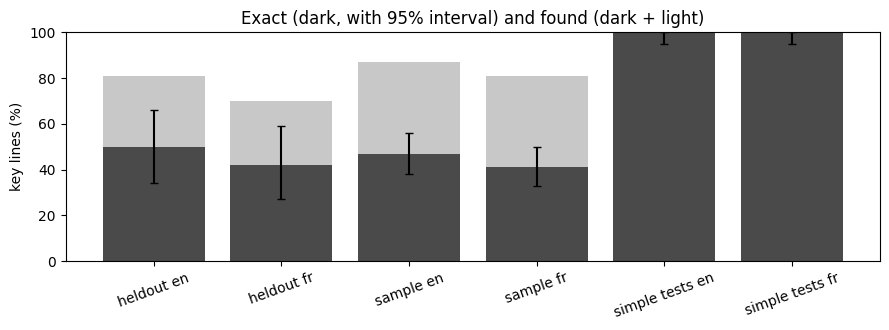

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.4))
vals = DS["exact %"].values; lohi = [tuple(map(float, s.split(" to "))) for s in DS["exact 95% interval"]]
ax.bar(DS["set"], vals, color="#4a4a4a", yerr=[[max(0, v - a) for v, (a, b) in zip(vals, lohi)], [max(0, b - v) for v, (a, b) in zip(vals, lohi)]], capsize=3)
ax.bar(DS["set"], DS["found %"] - vals, bottom=vals, color="#c8c8c8")
ax.set_ylim(0, 100); ax.set_ylabel("key lines (%)"); ax.set_title("Exact (dark, with 95% interval) and found (dark + light)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### The 45 simple test pairs, one construction each

In [15]:
rows_c = []
for t in PT.T:
    for lang in ("en", "fr"):
        n = f"test|{t['id']}|{lang}"
        key = key_lines(t, lang)
        f_, e_ = marks(key, as_dicts(OUT[n])) if key else ([], [])
        rows_c.append(dict(pair=t["id"], group=t["group"], construction=t["construction"], lang=lang, found=all(f_) if key else not OUT[n]["lines"],
                           exact=all(e_) if key else not OUT[n]["lines"],
                           expected=" / ".join(" | ".join(map(str, k[:3])) for k in key) or "(none)",
                           output=" / ".join(f"{a} | {b} | {c}" for a, b, c in lines_of(n)) or "(none)"))
DCt = pd.DataFrame(rows_c)
display(DCt.groupby(["group", "lang"])[["found", "exact"]].mean().mul(100).round(0))
print("pairs not exactly right:")
display(DCt[~DCt.exact][["pair", "lang", "construction", "expected", "output"]])

found  exact
group     lang              
clauses   en    100.0  100.0
          fr    100.0  100.0
hedge     en    100.0  100.0
          fr    100.0  100.0
negation  en    100.0  100.0
          fr    100.0  100.0
relative  en    100.0  100.0
          fr    100.0  100.0
reported  en    100.0  100.0
          fr    100.0  100.0
structure en    100.0  100.0
          fr    100.0  100.0

pairs not exactly right:


,pair,lang,construction,expected,output


### What kind of mistake each miss is

In [16]:
def classify(k, lines):
    kv = P.fold(k[1])[-1:]
    cand = [x for x in lines if kv and (kv[0] in P.fold(x["verb"]) or any(w[:4] == kv[0][:4] for w in P.fold(x["verb"])))]
    if not cand:
        return "no line with that verb"
    so = lambda x: bool(P.content(k[0].replace("(inh)", "")) & P.content(x["subject"])) or nm(k[0]) == nm(x["subject"])
    oo = lambda x: nm(P._no_note(k[2])) == nm(x["object"]) or bool(P.content(P._no_note(k[2])) & P.content(x["object"]))
    b = max(cand, key=lambda x: (so(x), oo(x)))
    if P.gold_negated(k) != bool(b["negated"]):
        return "negation differs"
    return {(False, False): "subject and object wrong", (False, True): "subject wrong", (True, False): "object wrong"}.get((so(b), oo(b)), "right words, not word for word")
err = collections.defaultdict(collections.Counter); EX = collections.defaultdict(list)
for r in ROWS:
    key = key_of(r)
    L_ = as_dicts(OUT[r["n"]]); ex = {(nm(x["subject"]), nm(x["verb"]), nm(x["object"])) for x in L_}
    for k in key:
        if (nm(k[0]), nm(k[1]), nm(P._no_note(k[2]))) in ex:
            err[group(r)]["exact"] += 1
        else:
            c = classify(k, L_); err[group(r)][c] += 1; EX[c].append((r["n"], " | ".join(map(str, k[:3]))))
display(pd.DataFrame(err).T.fillna(0).astype(int))
for c, xs in EX.items():
    print(f"\n{c} (first 5):")
    for n, k in xs[:5]:
        print(f"   {n:14s} key: {k[:110]}")

,exact,object wrong,"right words, not word for word",subject wrong,subject and object wrong,no line with that verb,negation differs
simple tests en,70,0,0,0,0,0,0
simple tests fr,70,0,0,0,0,0,0
heldout en,18,2,11,3,1,1,0
heldout fr,14,6,9,3,1,0,0
sample en,56,6,42,7,0,7,1
sample fr,48,7,42,7,2,8,2



object wrong (first 5):
   heldout|1      key: They | are not staffed | like they are on the units
   heldout|3      key: we | are setting up | what (a 50-State lawsuit form)
   heldout|16     key: ce | n'est pas | tout à fait ce que les gens s'attendaient
   heldout|18     key: je | vais m'adresser | à ma vis-à-vis
   heldout|18     key: je | salue | le député de René-Lévesque (que)

right words, not word for word (first 5):
   heldout|2      key: I | thank | the gentleman for his leadership on this important issue
   heldout|3      key: I | do not want to discount | the fact that health care needs to be improved
   heldout|4      key: the ones who are free to disagree | are | his fellow Republicans
   heldout|4      key: the ones | are | free to disagree
   heldout|6      key: Repealing the Liberals' 2009 Green Energy Act | will make | life more affordable in this province

subject wrong (first 5):
   heldout|7      key: important measures (inh) | help | us better prevent, detect an

### Each rule switched off, one at a time

A rule earns its place when switching it off loses key lines. The discourse rules (step 4) are listed first.

In [17]:
def totals(out):
    t = collections.Counter()
    for r in ROWS:
        key = key_of(r)
        if not key:
            continue
        g = "held-out" if r["set"] == "heldout" else ("simple tests" if r["set"] == "test" else "sample")
        f_, e_ = marks(key, as_dicts(out[r["n"]]))
        t[g, "found"] += sum(f_); t[g, "exact"] += sum(e_); t[g, "key"] += len(key)
    return t
base = totals(OUT)
DISCOURSE_RULES = ["discourse_subject", "demonstrative", "relpron", "said_object", "frame_context"]
UNIT_RULES = [k for k in E.OPT if k not in DISCOURSE_RULES + ["units_only"] + list(E.SENTENCE_TREE_RULES)]
abl = []
for rule in DISCOURSE_RULES + UNIT_RULES:
    s = totals({r["n"]: run(r, TREES[r["n"]], {rule: False}) for r in ROWS})
    abl.append({"rule switched off": rule, "step": "4 (discourse)" if rule in DISCOURSE_RULES else "3 (unit tree)",
                **{f"{g} {m}": s[g, m] - base[g, m] for g in ("sample", "held-out", "simple tests") for m in ("found", "exact")}})
DA = pd.DataFrame(abl)
print("change in key lines when the rule is off (negative = the rule helps):")
display(DA)
off = {r["n"]: run(r, TREES[r["n"]], {k: False for k in DISCOURSE_RULES}) for r in ROWS}
s = totals(off)
print("all of step 4 off (units read alone, nothing connected):",
      {g: f"found {s[g, 'found'] - base[g, 'found']:+d}, exact {s[g, 'exact'] - base[g, 'exact']:+d}" for g in ("sample", "held-out", "simple tests")})

change in key lines when the rule is off (negative = the rule helps):


,rule switched off,step,sample found,sample exact,held-out found,held-out exact,simple tests found,simple tests exact
0,discourse_subject,4 (discourse),-37,-13,-5,-3,-16,-16
1,demonstrative,4 (discourse),0,0,0,0,0,0
2,relpron,4 (discourse),-6,-5,-2,-1,0,0
3,said_object,4 (discourse),-8,-3,-4,-3,-7,-7
4,frame_context,4 (discourse),0,0,0,0,0,0
5,collapse,3 (unit tree),0,0,0,0,0,0
6,drop_address,3 (unit tree),0,0,-3,-2,-1,-1
7,unwrap_coord,3 (unit tree),-3,0,0,0,0,0
8,fix_verb,3 (unit tree),-5,0,-1,-2,-4,-2
9,tree_subject,3 (unit tree),-2,-1,-2,-1,-1,-1


all of step 4 off (units read alone, nothing connected): {'sample': 'found -48, exact -20', 'held-out': 'found -11, exact -7', 'simple tests': 'found -23, exact -23'}


### Units parsed on their own vs cut from the sentence's tree

Once `run_edu.sh` has parsed every unit on its own, this compares the lines from those trees with the lines from the stand-in (the sentence's tree cut to the unit).

In [18]:
if not REPARSED:
    print("skipped: units have not been parsed on their own yet (run scripts/v6/run_edu.sh on the Mac)")
else:
    CUT = {r["n"]: run(r, [[t for t, _ in ps] for ps in E.unit_trees(r, edus_of(r))]) for r in ROWS}
    display(pd.concat([score_table(OUT, "units parsed on their own"), score_table(CUT, "stand-in: cut from the sentence")]).sort_values(["set", "design"]))
    diff = [n for n in OUT if [(l["subject"], l["verb"], l["object"]) for l in OUT[n]["lines"]] != [(l["subject"], l["verb"], l["object"]) for l in CUT[n]["lines"]]]
    print(f"sentences whose lines differ: {len(diff)} of {len(OUT)}")
    for n in diff[:8]:
        print(f"\n{n}: {BY_N[n]['text'][:110]}\n   parsed alone: {[(l['subject'], l['verb'], l['object']) for l in OUT[n]['lines']]}\n   cut:          {[(l['subject'], l['verb'], l['object']) for l in CUT[n]['lines']]}")

,set,design,key lines,found %,exact %,exact 95% interval
0,heldout en,stand-in: cut from the sentence,36,81,50,34 to 66
0,heldout en,units parsed on their own,36,81,50,34 to 66
1,heldout fr,stand-in: cut from the sentence,33,73,42,27 to 59
1,heldout fr,units parsed on their own,33,70,42,27 to 59
2,sample en,stand-in: cut from the sentence,119,87,49,40 to 58
2,sample en,units parsed on their own,119,87,47,38 to 56
3,sample fr,stand-in: cut from the sentence,116,80,41,32 to 50
3,sample fr,units parsed on their own,116,81,41,33 to 50
4,simple tests en,stand-in: cut from the sentence,70,100,100,95 to 100
4,simple tests en,units parsed on their own,70,100,100,95 to 100


sentences whose lines differ: 27 of 220

test|E6|fr: Le comité décidera si le projet de loi va de l'avant.
   parsed alone: [('Le comité', 'décidera', "si le projet de loi va de l'avant"), ('le projet de loi', 'va', "de l'avant")]
   cut:          [('Le comité', 'décidera', "si le projet de loi va de l'avant"), ('le projet de loi', 'va', '')]

test|F2|fr: Le projet de loi que la Chambre a adopté réduit les coûts.
   parsed alone: [('la Chambre', 'a adopté', 'Le projet de loi'), ('Le projet de loi', 'réduit', 'les coûts')]
   cut:          [('la Chambre', 'a adopté', 'que la Chambre a adopté (que)'), ('Le projet de loi', 'réduit', 'les coûts')]

heldout|7: If passed, this proposed Animal Health Act would provide important measures to help us better prevent, detect 
   parsed alone: [('this proposed Animal Health Act', 'would provide', 'important measures'), ('this proposed Animal Health Act', 'help', 'us'), ('this proposed Animal Health Act', 'prevent detect respond', 'to')]
   cut:    

### To check by hand

Fifteen debate sentences drawn at random (seed 20261026), saved as `outputs/edu/hand_check.csv` with empty "Right?" and "What it should be" columns.

In [19]:
rnd = random.Random(20261026)
pool = [n for n in OUT if BY_N[n]["set"] in ("sample", "heldout")]
pick = sorted(rnd.sample(pool, 15), key=pool.index)
hc = []
for n in pick:
    x = OUT[n]
    for l in x["lines"]:
        hc.append({"ID": n, "Unit": l["unit"], "Unit text": x["units"][l["unit"]]["text"], "Subject": l["subject"], "Verb": l["verb"], "Object": l["object"],
                   "Where the subject came from": l.get("subject_from") or "its own unit", "Right?": "", "What it should be": ""})
    for c in x["connections"]:
        hc.append({"ID": n, "Unit": c["from"] + " to " + c["to"], "Unit text": "", "Subject": "", "Verb": c["relation"], "Object": "",
                   "Where the subject came from": "discourse parse", "Right?": "", "What it should be": ""})
pd.DataFrame(hc).to_csv(OUTDIR / "hand_check.csv", index=False)
print(f"saved {OUTDIR / 'hand_check.csv'} ({len(hc)} rows from {len(pick)} sentences)")
display(pd.DataFrame(hc).head(20))

saved /Users/caprice/MiscellaneousProjects/legislative-health-factuality/outputs/edu/hand_check.csv (71 rows from 15 sentences)


,ID,Unit,Unit text,Subject,Verb,Object,Where the subject came from,Right?,What it should be
0,heldout|3,0,And I do not want to discount the fact,I,do not want to discount,the fact,its own unit,,
1,heldout|3,1,"that health care needs to be improved,",health care,needs to be improved,,its own unit,,
2,heldout|3,2,but I am a lawyer,I,am,a lawyer,its own unit,,
3,heldout|3,3,and I know what we are setting up with a 50-State lawsuit form.,I,know,what we are setting up with a 50-State lawsuit form,its own unit,,
4,heldout|3,3,and I know what we are setting up with a 50-State lawsuit form.,we,are setting up,with a 50-State lawsuit form,its own unit,,
5,heldout|3,unit 0 to unit 1,,,elaboration,,discourse parse,,
6,heldout|3,unit 2 to unit 3,,,joint,,discourse parse,,
7,heldout|3,unit 0 and unit 1 to unit 2 and unit 3,,,contrast,,discourse parse,,
8,heldout|23,0,"Mais voilà, les engagements libéraux,",,voilà,les engagements libéraux,its own unit,,
9,heldout|23,1,alors que le Parti libéral du Québec s'est présenté,le Parti libéral du Québec,s'est présenté,,its own unit,,


## Summary

In [20]:
st = collections.Counter(s for _, s in RESULTS)
print(f"checks and rule tests: {st['PASS']} pass, {st['FAIL']} fail")
for name, s in RESULTS:
    if s != "PASS":
        print("   FAIL:", name)
print("trees:", "parsed now" if LIVE else ("units parsed on their own (saved)" if REPARSED else "STAND-INS cut from the sentence's tree; run run_edu.sh on the Mac for the real per-unit parses"))
print(DS[["set", "found %", "exact %", "exact 95% interval"]].to_string(index=False))

checks and rule tests: 111 pass, 0 fail
trees: parsed now
            set  found %  exact % exact 95% interval
     heldout en       81       50           34 to 66
     heldout fr       70       42           27 to 59
      sample en       87       47           38 to 56
      sample fr       81       41           33 to 50
simple tests en      100      100          95 to 100
simple tests fr      100      100          95 to 100
